# RFM vs. CellFlow on EB differentiation, fixed-Gaussian kernel: the 3-gene and the 3-PC scenario

**Contents.** The four-way comparison of `riemannian_eb_genes_example.ipynb`, run on the two 3-dimensional scenarios of `data/eb_ot_v2.ipynb`:

| Scenario | Coordinates | Selected by |
| --- | --- | --- |
| **3 genes** | RPL12, VIM, COL3A1: log-expression after `normalize_total(1e4)` and `log1p` | greedy kNN time structure among highly variable, time-dependent genes |
| **3 PCs** | PC1, PC2, PC6 of a 50-component PCA fitted on the benchmark's training cells (`data/eb_ot_v2/eb_pca.npz`) | the same greedy selection among the 50 components |

Both scenarios use the same four models, trained from the $t=0$ cells (source) to the $t=1$ cells (target) of the training split:

| | Biharmonic OT coupling | Euclidean OT coupling |
| --- | --- | --- |
| **Riemannian FM** (`solver="otrfm"`) | RFM + biharmonic OT | RFM + Euclidean OT |
| **Euclidean FM** (`solver="otfm"`) | FM + biharmonic OT | **FM + Euclidean OT** = standard CellFlow |

For each scenario, the notebook shows:

1. **The data** as 3-D point clouds coloured by experimental time.
2. **The reference vector fields** for one pair of points $(x_0, x_1)$: the medoids of the training graph points at $t=0$ and $t=1$. These are the conditional target fields that each method regresses onto:
   - Euclidean FM: $u_t(x\mid x_1)=(x_1-x)/(1-t)$, whose integral curve from $x_0$ is the straight line;
   - RFM: $u_t(x\mid x_1)=-\,d(x,x_1)\,\nabla d(x,x_1)/\big(\|\nabla d(x,x_1)\|^2(1-t)\big)$ with the biharmonic distance $d$, integrated by Euler steps.

   Both fields are shown at $t=0$. Their direction does not depend on $t$; only their magnitude scales with $1/(1-t)$.
3. **The learned vector fields** $v_\theta(t,x)$ of all four variants at $t = 0, 0.5, 1$, and the learned trajectories.
4. **The comparison metrics**: endpoints at $t=1$, and the intermediate days $t=0.25, 0.5, 0.75$, on held-out cells.

**Settings.** Everything follows `riemannian_eb_genes_example.ipynb` (split, graph, kernel, network, OT, training), with four exceptions:

- **All cells are kept.** No "expresses all three genes" filter is applied.
- **Only the fixed-Gaussian kernel is fitted.** It weights an edge by $\exp(-\|x-y\|^2/(2\sigma^2))$ with one global $\sigma$: the median distance of the graph points to their 24 nearest neighbours. The support is the same CkNN support $\|x-y\|^2<\delta^2\rho_x\rho_y$ as for the variable Gaussian, so the support diagnostics do not depend on the profile. The companion notebook `riemannian_eb_scenarios_3d.ipynb` runs the variable-Gaussian kernel with otherwise identical settings. **In the gene view the fixed-Gaussian graph is disconnected**, so only the 3-PC view gets the comparison; section 4b shows why.
- **The 3-PC view is not clipped.** PCA scores are signed, so the clip to $x\ge 0$ after each RFM interpolation step is used for the gene view only.
- **The ODE step limit is raised.** Predictions and paths use the predictor's Tsit5 solver and tolerances, but with up to 100,000 adaptive steps instead of 4,096. The RFM fields of the PCA view are stiff near $t=0$. The tables report the steps used.
- **The RFM velocity cap is scaled to the data.** It is 10 × the mean distance between independent $t=0$ and $t=1$ training cells. In the original MDK/RPL12/VIM view this gives about 26, close to its fixed cap of 30. The PCA coordinates span a larger range than log-expression values.

Run from `CellFlow/docs/notebooks`.

In [1]:
# 1 · imports and settings
import os

os.environ.setdefault("TQDM_DISABLE", "1")   # no per-iteration progress bars in the saved notebook
import json
import warnings

import anndata as ad
import diffrax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import pandas as pd
import scanpy as sc
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

from cellflow.ode_solver import RFMInterpolation
from riemannian_toys import cells, comparison, flows, kernels, plotting

warnings.simplefilter("ignore", FutureWarning)

DATA_DIR = "/ictstr01/groups/ml01/workspace/markus.laengst/data/eb_ot_v2"
if not os.path.exists(DATA_DIR):   # the GPU nodes mount the same workspace under /lustre
    DATA_DIR = DATA_DIR.replace("/ictstr01/", "/lustre/", 1)

# as in riemannian_eb_genes_example.ipynb
split_fractions, split_seed = {"train": 0.7, "val": 0.1, "test": 0.2}, 0
graph_max_cells, graph_seed = 4000, 0
kernel_name = "fixed Gaussian"
kernel_settings = {"density_k": 24, "delta": 2.0, "n_modes": 32, "laplacian_type": "unnormalized",
                   "spectral_weight_type": "biharmonic"}
ot_epsilon, batch_size, interpolation_steps, num_iterations, seed = 0.05, 64, 32, 1000, 2026
source_time, target_time = 0.0, 1.0
target_key, condition_name = "day_1", "t=1 cells"
max_ode_steps = 100_000        # adaptive Tsit5 steps per cell; diffrax's default 4,096 is too few for the stiffest RFM fields
velocity_cap_factor = 10.0     # RFM speed cap = factor × mean distance between independent t=0 and t=1 training cells

# velocity field: parameters.json["model"], adapted as in riemannian_eb_genes_example.ipynb
architecture = {
    "condition_mode": "deterministic",
    "regularization": 0.0,
    "pooling": "attention_token",
    "pooling_kwargs": {},
    "layers_before_pool": {"transport": [{"layer_type": "mlp", "dims": (512, 512), "dropout_rate": 0.5}]},
    "layers_after_pool": [{"layer_type": "mlp", "dims": (512, 512), "dropout_rate": 0.1}],
    "condition_embedding_dim": 128,
    "cond_output_dropout": 0.3,
    "condition_encoder_kwargs": {},
    "pool_sample_covariates": True,
    "time_freqs": 1024,
    "time_encoder_dims": (512, 512),
    "time_encoder_dropout": 0.1,
    "hidden_dims": (512, 512),
    "hidden_dropout": 0.2,
    "conditioning": "film",
    "decoder_dims": (1024, 1024),
    "vf_act_fn": jax.nn.silu,
    "layer_norm_before_concatenation": False,
    "linear_projection_before_concatenation": False,
}
MODEL_COLORS = {"RFM + biharmonic OT": "tab:green", "RFM + Euclidean OT": "tab:cyan",
                "FM + biharmonic OT": "tab:purple", "FM + Euclidean OT": "tab:pink"}
CELLFLOW = "FM + Euclidean OT"
print("jax devices:", jax.devices())

jax devices: [CudaDevice(id=0)]


## The data in both views

Both views use all 18,203 cells and the same split: 70% train, 10% validation and 20% test within every time point (the RFM notebook's `stratified_group_split`, seed 0).

In [2]:
# 2 · data, the two views, split
adata = ad.read_h5ad(f"{DATA_DIR}/eb_prepared.h5ad")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
scen = json.load(open(f"{DATA_DIR}/eb_scenarios.json"))
pz = np.load(f"{DATA_DIR}/eb_pca.npz")
assert (pz["obs_names"] == adata.obs_names.to_numpy(dtype=str)).all()

time = adata.obs["experimental_time"].to_numpy(np.float64)
time_levels = np.unique(time)
S = {
    "3 genes": {"X": cells.gene_view(adata, scen["genes"]["3"]["var_names"]),
                "labels": list(scen["genes"]["3"]["symbols"]), "clip": True, "unit": "log-expression"},
    "3 PCs": {"X": np.ascontiguousarray(pz["scores"][:, scen["pca"]["time_selected"]["3"]["pcs"]], dtype=np.float32),
              "labels": list(scen["pca"]["time_selected"]["3"]["labels"]), "clip": False, "unit": "PC score"},
}
split = cells.stratified_group_split(time, adata.obs["duplicate_group"].astype(str).to_numpy(), split_fractions, split_seed)
display(cells.split_table(split, time))


def cells_at(s, split_name, t):
    return s["X"][(split == split_name) & np.isclose(time, t)]


view_rows = {}
for name, s in S.items():
    X = s["X"]
    lo, hi = np.quantile(X, 0.002, axis=0), np.quantile(X, 0.998, axis=0)
    pad = 0.04 * (hi - lo)
    s["lims"] = list(zip(lo - pad, hi + pad))
    s["extent"] = float((hi - lo).max())
    s["day_means"] = np.vstack([X[np.isclose(time, t)].mean(0) for t in time_levels])
    s["bg_ids"] = np.random.default_rng(0).choice(len(X), 3000, replace=False)
    view_rows[name] = {
        "coordinates": ", ".join(s["labels"]),
        "zero fraction per coordinate": ", ".join(f"{v:.2f}" for v in (X == 0).mean(0)),
        "range per coordinate": ", ".join(f"[{a:.1f}, {b:.1f}]" for a, b in zip(X.min(0), X.max(0))),
        "distinct points": len(cells.unique_points(X)[1]),
    }
display(pd.DataFrame(view_rows).T)

time,0.0,0.25,0.5,0.75,1.0,All
split,,,,,,
train,1859,3062,2555,2711,2555,12742
val,266,437,365,387,365,1820
test,531,875,730,775,730,3641
All,2656,4374,3650,3873,3650,18203


,coordinates,zero fraction per coordinate,range per coordinate,distinct points
3 genes,"RPL12, VIM, COL3A1","0.00, 0.08, 0.63","[0.0, 7.2], [0.0, 7.7], [0.0, 6.6]",17898
3 PCs,"PC1, PC2, PC6","0.00, 0.00, 0.00","[-13.7, 22.4], [-10.2, 16.2], [-13.4, 12.1]",18203


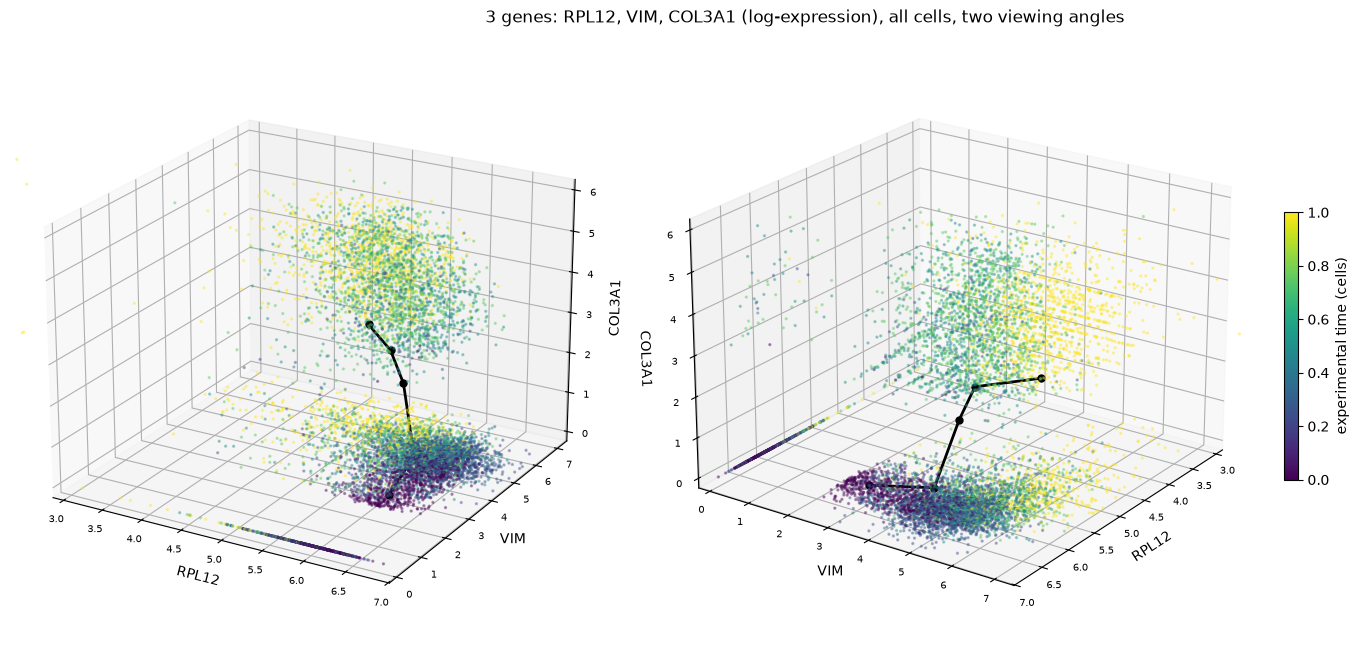

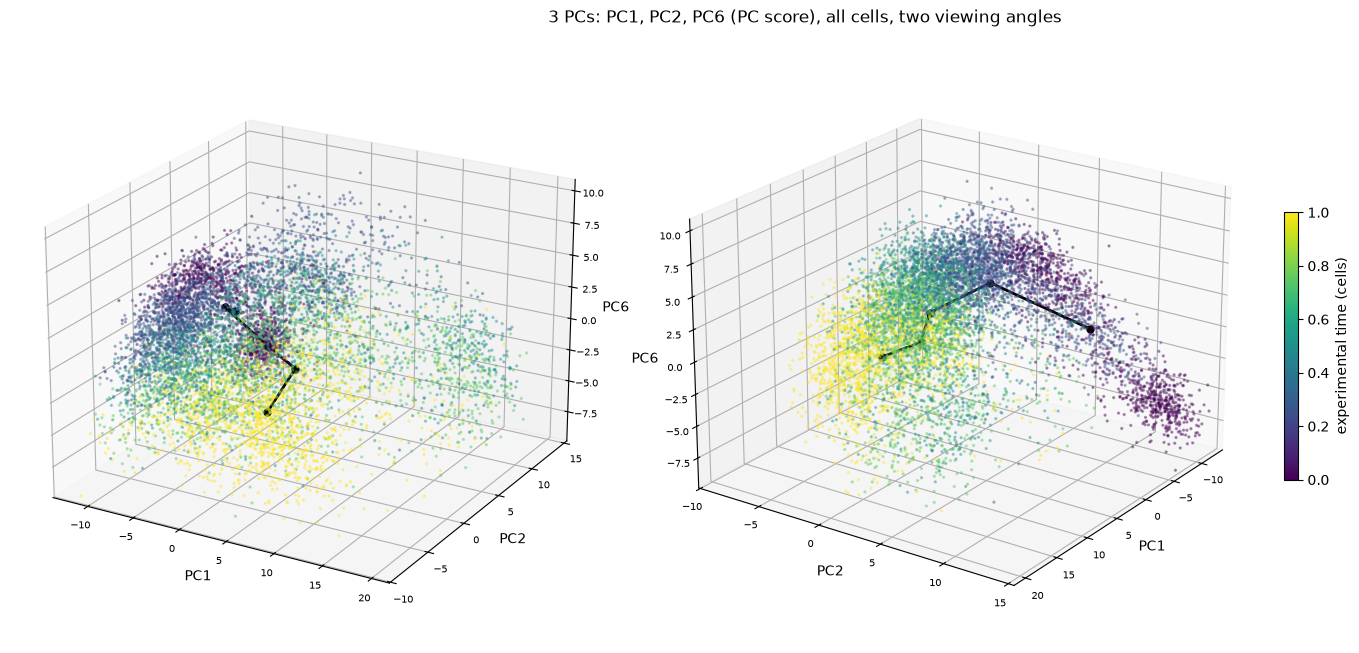

In [3]:
# 3 · 3-D views of the data (subsample of 8,000 cells; black: mean per time point)
TIME_NORM = Normalize(0.0, 1.0)


def setup_axes(ax, s, elev=22, azim=-60):
    ax.set(xlim=s["lims"][0], ylim=s["lims"][1], zlim=s["lims"][2])
    ax.set_xlabel(s["labels"][0], labelpad=-1)
    ax.set_ylabel(s["labels"][1], labelpad=-1)
    ax.set_zlabel(s["labels"][2], labelpad=-1)
    ax.tick_params(labelsize=7, pad=0)
    ax.view_init(elev=elev, azim=azim)


def time_colorbar(fig, axes, label="experimental time (cells)"):
    fig.colorbar(ScalarMappable(TIME_NORM, "viridis"), ax=axes, shrink=0.45, pad=0.02, label=label)


for name, s in S.items():
    ids = np.random.default_rng(1).choice(len(time), 8000, replace=False)
    fig = plt.figure(figsize=(17, 6.6))
    axes = []
    for k, azim in enumerate((-60, 35)):
        ax = fig.add_subplot(1, 2, k + 1, projection="3d")
        ax.scatter(*s["X"][ids].T, c=time[ids], cmap="viridis", norm=TIME_NORM, s=2, alpha=0.35, depthshade=False,
                   rasterized=True)
        ax.plot(*s["day_means"].T, "k-o", ms=5, lw=2)
        setup_axes(ax, s, azim=azim)
        axes.append(ax)
    fig.subplots_adjust(left=0.0, right=0.92, top=0.92, bottom=0.02, wspace=0.0)
    time_colorbar(fig, axes)
    fig.suptitle(f"{name}: {', '.join(s['labels'])} ({s['unit']}), all cells, two viewing angles")
    plt.show()

## Graph and biharmonic geometry

The graph uses 4,000 training cells drawn over all five time points, reduced to their distinct points. Validation and test cells never enter it. The fixed-Gaussian kernel ($\sigma$ = the median 24-nearest-neighbour distance, on the CkNN support with $k_\rho=24$ and $\delta=2$) gives 32 biharmonic modes and a continuous Nyström extension. Unlike the variable Gaussian, it does not adapt to the local density: cells in sparse regions are farther than $\sigma$ from their neighbours and get edge weights close to zero.

`lambda_2`, the smallest non-zero eigenvalue of the graph Laplacian, measures how well connected the graph is: a small value means a bottleneck. The biharmonic coordinate $\Psi_2=\phi_2/\lambda_2$ then dominates every distance.

`fit_kernel_nystroem` refuses a disconnected graph. A view whose fixed-Gaussian graph falls apart is therefore dropped from the comparison, and the cell after the table shows why.

In [4]:
# 4 · graph, kernel and Nyström extension per view; RFM velocity cap
train_ids = np.flatnonzero(split == "train")
graph_ids = np.sort(np.random.default_rng(graph_seed).choice(train_ids, graph_max_cells, replace=False))
assert set(split[graph_ids]) == {"train"}

geometry_rows, dropped = {}, {}
for name, s in list(S.items()):
    points, counts, inverse = cells.unique_points(s["X"][graph_ids])
    point_time = np.bincount(inverse, weights=time[graph_ids]) / counts
    try:
        models, fitted, _, fit_df = kernels.fit_kernel_profiles(points, {kernel_name: kernels.KERNEL_PROFILES[kernel_name]},
                                                                **kernel_settings)
    except ValueError as error:     # disconnected graph
        dropped[name] = (str(error), points)
        continue
    s.update(points=points, point_time=point_time, nystroem=models[kernel_name])
    s["cloud"] = cells.CellCloud(points, fitted[kernel_name])
    s["project"] = cells.CellCloud.project if s["clip"] else None
    src, tgt = cells_at(s, "train", source_time), cells_at(s, "train", target_time)
    rng = np.random.default_rng(0)
    pair_dist = np.linalg.norm(src[rng.integers(len(src), size=5000)] - tgt[rng.integers(len(tgt), size=5000)], axis=1)
    s["velocity_cap"] = float(velocity_cap_factor * pair_dist.mean())
    psi = np.asarray(s["nystroem"].Psi)
    geometry_rows[name] = {
        "distinct graph points": len(points),
        **fit_df.loc[kernel_name, ["edges", "components", "min_degree", "median_degree", "lambda_2"]].to_dict(),
        **{f"|spearman(Psi_{k + 1}, time)|": abs(spearmanr(psi[:, k], point_time)[0]) for k in range(3)},
        **{f"{sp} cells in support": float(s["cloud"].contains(s["X"][split == sp]).mean()) for sp in cells.SPLITS},
        "mean distance t=0 to t=1 cells": float(pair_dist.mean()),
        "RFM velocity cap": s["velocity_cap"],
        "kernel sigma": float(fitted[kernel_name].sigma),
    }
display(pd.DataFrame(geometry_rows).round(4))

fixed Gaussian: fitted in 2.94s


,3 PCs
distinct graph points,4000.0000
edges,316342.0000
components,1.0000
min_degree,0.2147
median_degree,33.3066
lambda_2,0.0775
"|spearman(Psi_1, time)|",0.6945
"|spearman(Psi_2, time)|",0.2556
"|spearman(Psi_3, time)|",0.4682
train cells in support,1.0000


### Why the gene view has no fixed-Gaussian geometry

The next cell rebuilds the fixed-Gaussian graph of every dropped view with $\sigma$ at 1–4 × its default. For each factor it reports:

- the CkNN edges whose weight underflows to zero (float32), against the variable-Gaussian graph on the same support;
- the connected components;
- the smallest degree;
- $\lambda_2$ of the unnormalized Laplacian $L = D - W$.

In [5]:
# 4b · fixed-Gaussian graph of the dropped views: edges, components, lambda_2 for 1-4 × the default sigma
from scipy.sparse import diags
from scipy.sparse.csgraph import connected_components
from scipy.sparse.linalg import eigsh

from cellflow.preprocessing._kernels import SymmetricBandwidthKernel

support = {"density_k": kernel_settings["density_k"], "delta": kernel_settings["delta"]}
for name, (message, points) in dropped.items():
    print(f"{name}: not fitted ({message})")
    n_support = SymmetricBandwidthKernel(points, profile="gaussian", **support).graph().nnz // 2
    default_sigma = SymmetricBandwidthKernel(points, profile="fixed_gaussian", **support).sigma
    rows = {}
    for factor in (1.0, 2.0, 3.0, 4.0):
        graph = SymmetricBandwidthKernel(points, profile="fixed_gaussian", sigma=factor * default_sigma, **support).graph()
        n_components, labels = connected_components(graph, directed=False)
        degree = np.asarray(graph.sum(axis=1)).ravel()
        laplacian = (diags(degree) - graph).tocsc()
        eigenvalues = np.sort(eigsh(laplacian, k=3, sigma=-1e-8, which="LM", return_eigenvectors=False))
        rows[f"{factor:g} × sigma = {factor * default_sigma:.3f}"] = {
            "zero-weight CkNN edges": n_support - graph.nnz // 2,
            "components": n_components,
            "largest components": str(np.sort(np.bincount(labels))[::-1][:4].tolist()),
            "min degree": degree.min(),
            "lambda_2": eigenvalues[1],
        }
    display(pd.DataFrame(rows).T)
    S.pop(name)
print("views kept:", list(S))

3 genes: not fitted (fixed_gaussian: 6 components; increase density_k or delta.)


,zero-weight CkNN edges,components,largest components,min degree,lambda_2
1 × sigma = 0.144,533,6,"[2200, 1455, 302, 22]",0.0,-0.0
2 × sigma = 0.288,42,1,[3985],0.0,0.0
3 × sigma = 0.433,1,1,[3985],0.000044,0.0
4 × sigma = 0.577,0,1,[3985],0.004656,-0.0


views kept: ['3 PCs']


### The fixed-Gaussian graphs from four viewing angles

Nodes are the distinct graph points, i.e. training cells. The full graphs have 220k (genes) and 316k (PCs) edges, so each node draws only its four heaviest edges, shaded by $\log_{10}$ weight (dark = heavy). The views are three azimuths at 20° elevation and one near-top view.

- **Top row:** nodes coloured by experimental time.
- **Bottom row, gene view:** nodes coloured by connected component. In red are the CkNN support edges whose fixed-Gaussian weight underflows to zero: the edges that would have joined the components.
- **Bottom row, PCA view:** nodes coloured by degree, the sum of their edge weights. The fixed bandwidth leaves the sparse outer cells weakly attached.

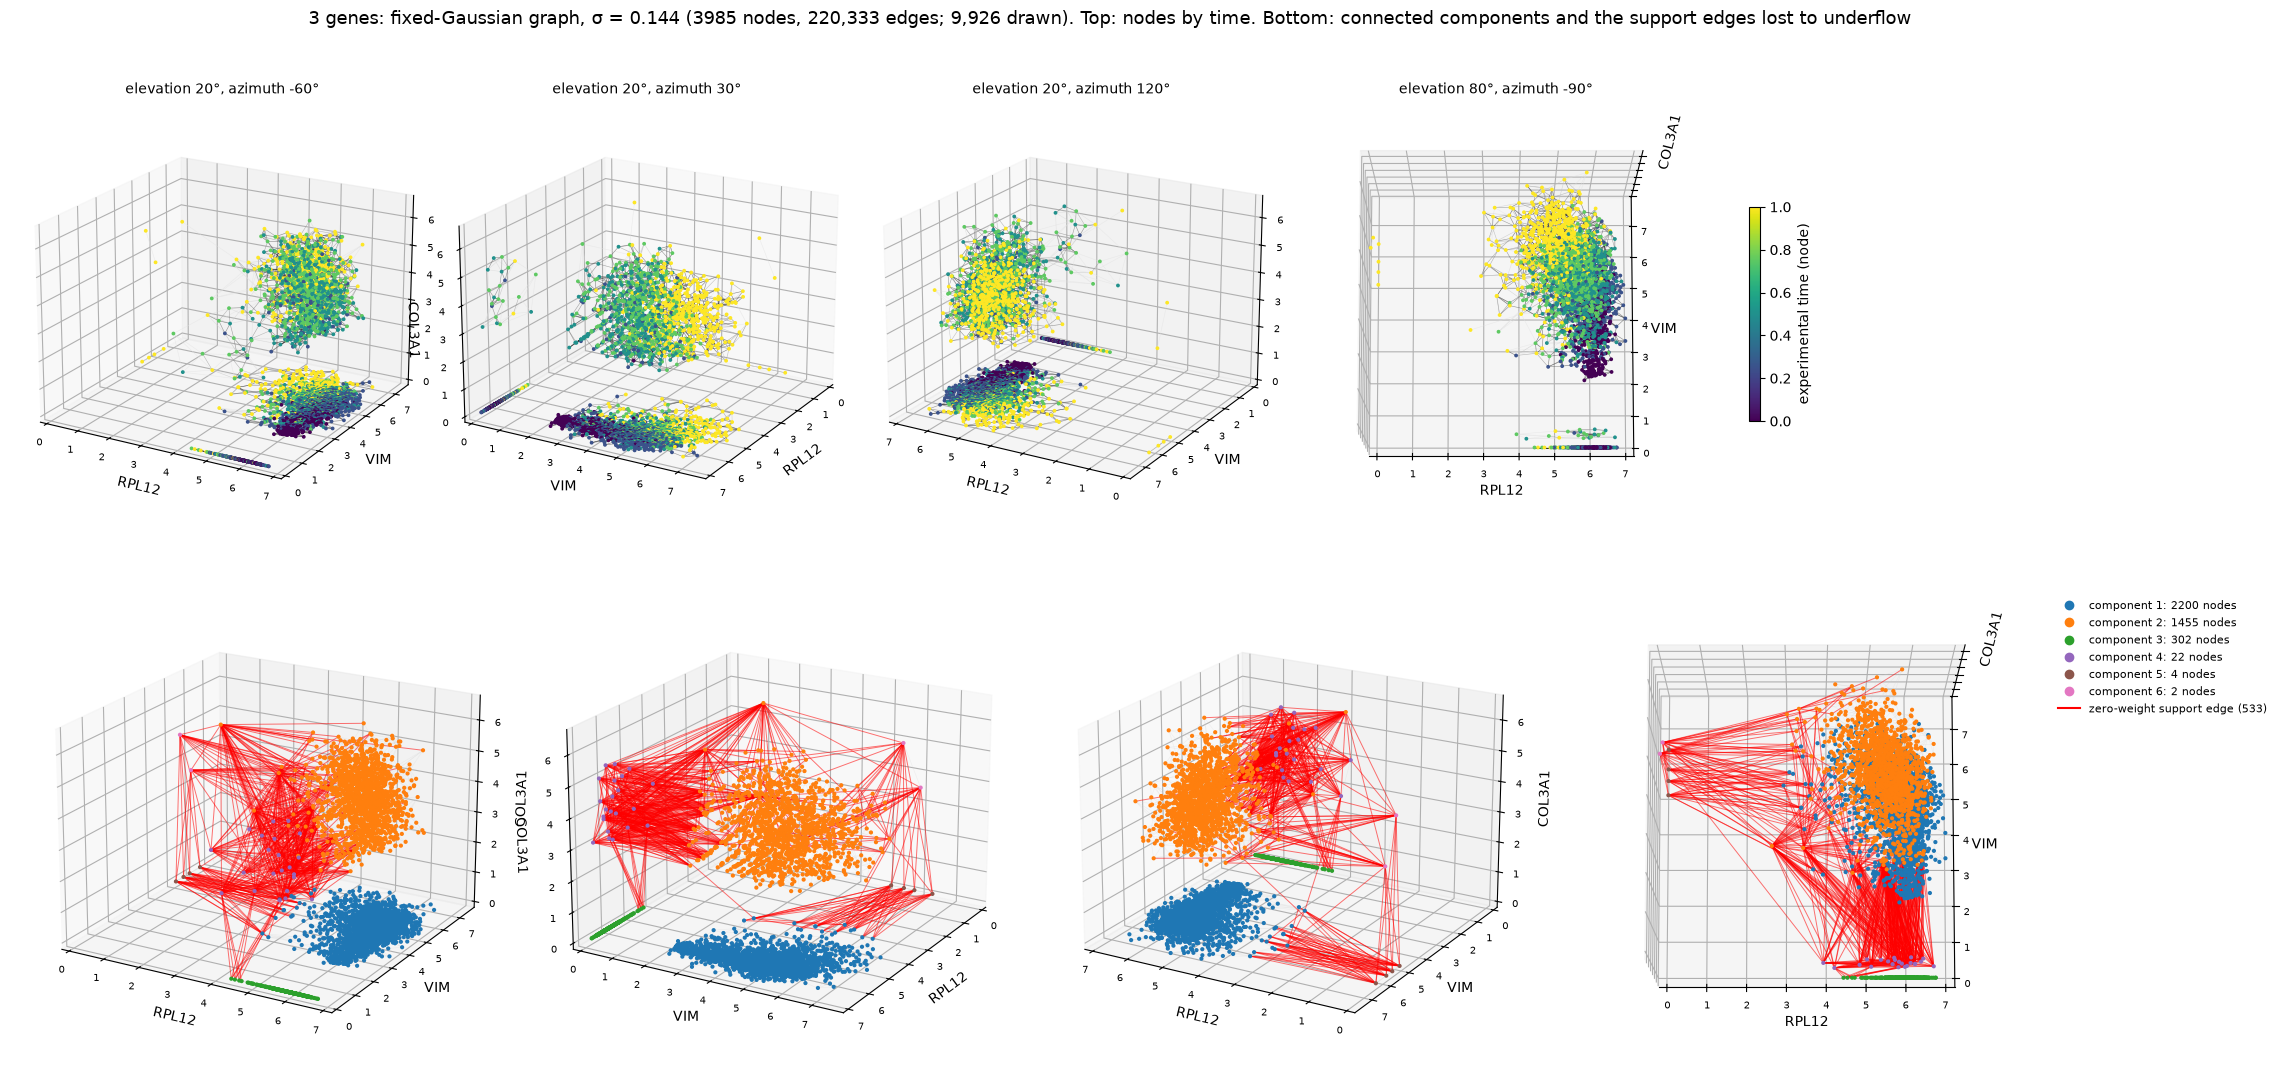

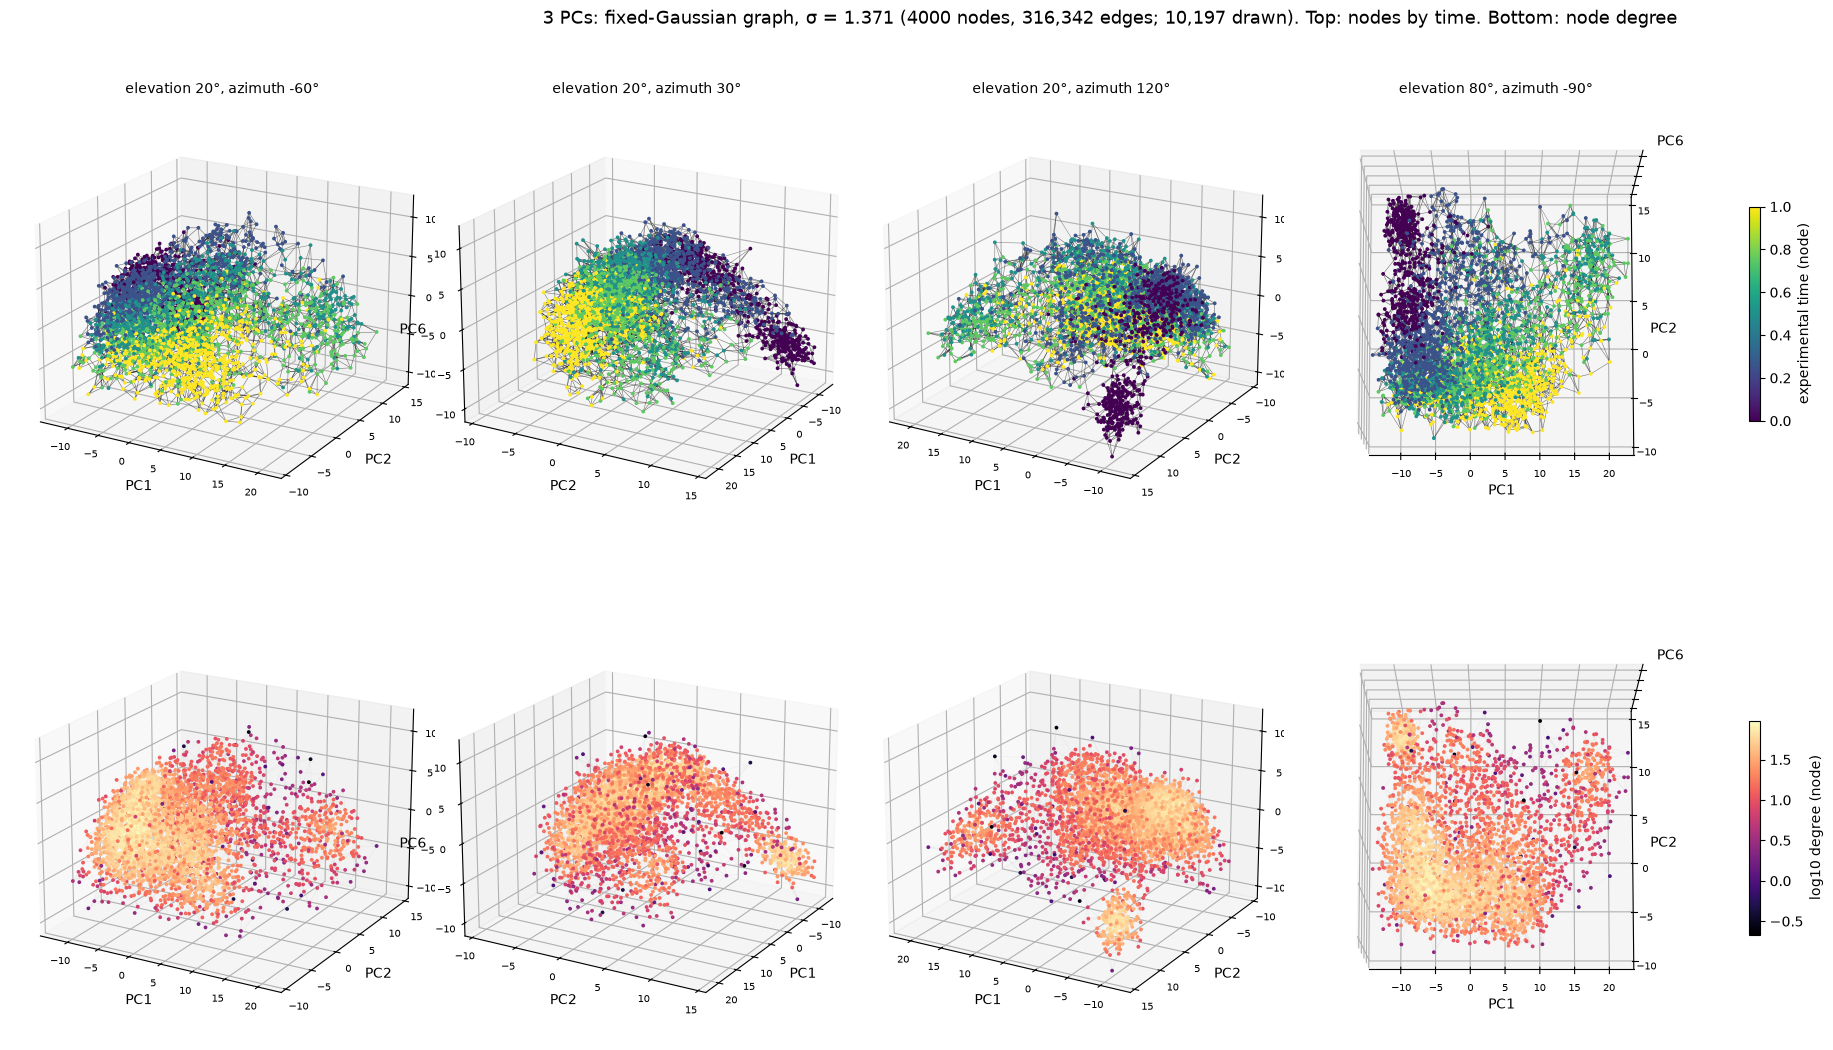

,3 genes,3 PCs
nodes,3.985000e+03,4000.000000
edges,2.203330e+05,316342.000000
zero-weight support edges,5.330000e+02,0.000000
components,6.000000e+00,1.000000
sigma,1.441702e-01,1.371472
min degree,2.634035e-40,0.214695
median degree,2.140684e+01,33.306625
nodes with degree < 1e-3,1.500000e+01,0.000000
median edge weight,2.898035e-02,0.157415
drawn edges,9.926000e+03,10197.000000


In [6]:
# 4c · the fixed-Gaussian graph of both views from four viewing angles
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.sparse import triu

VIEW_ANGLES = [(20, -60), (20, 30), (20, 120), (80, -90)]   # (elevation, azimuth)
WEIGHT_NORM = Normalize(-6.0, 0.0, clip=True)                # log10 edge weight; below 1e-6 drawn as the lightest grey


def strongest_edges(graph, per_node=4):
    # union of every node's per_node heaviest edges, as (i, j, weight) with i < j
    graph = graph.tocsr()
    pairs = []
    for i in range(graph.shape[0]):
        lo, hi = graph.indptr[i], graph.indptr[i + 1]
        top = np.argsort(graph.data[lo:hi])[::-1][:per_node]
        pairs += [(min(i, j), max(i, j)) for j in graph.indices[lo:hi][top]]
    pairs = np.unique(np.asarray(pairs), axis=0)
    return pairs[:, 0], pairs[:, 1], np.asarray(graph[pairs[:, 0], pairs[:, 1]]).ravel()


def add_edges(ax, points, a, b, colors, linewidth=0.4, alpha=0.6):
    ax.add_collection3d(Line3DCollection(np.stack([points[a], points[b]], axis=1), colors=colors,
                                         linewidths=linewidth, alpha=alpha))


def setup_graph_axes(ax, lims, labels, elev, azim):
    ax.set(xlim=lims[0], ylim=lims[1], zlim=lims[2])
    for setter, label in zip((ax.set_xlabel, ax.set_ylabel, ax.set_zlabel), labels):
        setter(label, labelpad=-1)
    ax.tick_params(labelsize=7, pad=0)
    ax.view_init(elev=elev, azim=azim)
    if elev >= 60:                                            # near-top view: the vertical axis is foreshortened
        ax.set_zticklabels([])


graph_views = {
    "3 genes": (cells.gene_view(adata, scen["genes"]["3"]["var_names"]), list(scen["genes"]["3"]["symbols"])),
    "3 PCs": (np.ascontiguousarray(pz["scores"][:, scen["pca"]["time_selected"]["3"]["pcs"]], dtype=np.float32),
              list(scen["pca"]["time_selected"]["3"]["labels"])),
}
graph_rows = {}
for name, (X, labels) in graph_views.items():
    points, counts, inverse = cells.unique_points(X[graph_ids])
    point_time = np.bincount(inverse, weights=time[graph_ids]) / counts
    kernel = SymmetricBandwidthKernel(points, profile="fixed_gaussian", **support)
    graph = kernel.graph()
    support_graph = SymmetricBandwidthKernel(points, profile="gaussian", **support).graph()
    lost = triu((support_graph > 0).astype(np.int8) - (graph > 0).astype(np.int8), k=1).tocoo()
    lost_a, lost_b = lost.row[lost.data > 0], lost.col[lost.data > 0]
    n_components, component = connected_components(graph, directed=False)
    degree = np.asarray(graph.sum(axis=1)).ravel()
    a, b, w = strongest_edges(graph)
    edge_colors = plt.get_cmap("Greys")(0.2 + 0.8 * WEIGHT_NORM(np.log10(w)))
    lo, hi = points.min(axis=0), points.max(axis=0)          # every node inside the box (3-D lines are not clipped)
    lims = list(zip(lo - 0.03 * (hi - lo), hi + 0.03 * (hi - lo)))
    graph_rows[name] = {
        "nodes": len(points), "edges": graph.nnz // 2, "zero-weight support edges": len(lost_a),
        "components": n_components, "sigma": kernel.sigma,
        "min degree": degree.min(), "median degree": np.median(degree),
        "nodes with degree < 1e-3": int((degree < 1e-3).sum()),
        "median edge weight": float(np.median(graph.data)), "drawn edges": len(a),
    }

    fig = plt.figure(figsize=(22, 11))
    top_axes, bottom_axes = [], []
    for c, (elev, azim) in enumerate(VIEW_ANGLES):
        ax = fig.add_subplot(2, 4, c + 1, projection="3d")
        add_edges(ax, points, a, b, edge_colors)
        ax.scatter(*points.T, c=point_time, cmap="viridis", norm=TIME_NORM, s=3, depthshade=False)
        setup_graph_axes(ax, lims, labels, elev, azim)
        ax.set_title(f"elevation {elev}°, azimuth {azim}°", fontsize=10)
        top_axes.append(ax)

        ax = fig.add_subplot(2, 4, c + 5, projection="3d")
        if n_components > 1:
            sizes = np.bincount(component)
            rank = np.argsort(np.argsort(-sizes))                     # 0 = largest component
            palette = plt.matplotlib.colors.ListedColormap(               # tab10 without red (red marks lost edges)
                ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:brown", "tab:pink", "tab:olive", "tab:cyan",
                 "black"])
            node_colors = np.array([palette(rank[k]) if rank[k] < 9 else plt.matplotlib.colors.to_rgba("lightgrey")
                                    for k in component])
            add_edges(ax, points, a, b, "lightgrey", alpha=0.3)
            add_edges(ax, points, lost_a, lost_b, "red", linewidth=0.7, alpha=0.55)
            ax.scatter(*points.T, c=node_colors, s=4, depthshade=False)
        else:
            add_edges(ax, points, a, b, "lightgrey", alpha=0.3)
            ax.scatter(*points.T, c=np.log10(degree), cmap="magma", s=3, depthshade=False)
        setup_graph_axes(ax, lims, labels, elev, azim)
        bottom_axes.append(ax)

    fig.subplots_adjust(left=0.0, right=0.93, top=0.92, bottom=0.02, wspace=0.0, hspace=0.08)
    time_colorbar(fig, top_axes, label="experimental time (node)")
    if n_components > 1:
        order = np.argsort(-sizes)
        handles = [plt.Line2D([], [], ls="", marker="o", color=palette(r), label=f"component {r + 1}: {sizes[k]} nodes")
                   for r, k in enumerate(order[:min(9, n_components)])]
        handles.append(plt.Line2D([], [], color="red", label=f"zero-weight support edge ({len(lost_a)})"))
        bottom_axes[-1].legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8, frameon=False)
    else:
        fig.colorbar(ScalarMappable(Normalize(np.log10(degree).min(), np.log10(degree).max()), "magma"), ax=bottom_axes,
                     shrink=0.45, pad=0.02, label="log10 degree (node)")
    fig.suptitle(f"{name}: fixed-Gaussian graph, σ = {kernel.sigma:.3f} ({len(points)} nodes, {graph.nnz // 2:,} edges; "
                 f"{len(a):,} drawn). Top: nodes by time. Bottom: "
                 + ("connected components and the support edges lost to underflow" if n_components > 1 else "node degree"),
                 fontsize=13)
    plt.show()
display(pd.DataFrame(graph_rows))

## Reference vector fields for one pair of points

The pair consists of the medoids of the distinct training graph points at $t=0$ ($x_0$, blue circle) and at $t=1$ ($x_1$, red star). Both reference fields are evaluated at the same 250 graph points, 50 per time point.

- **Arrows** are proportional to the velocity, with one scale per panel: the 90th-percentile speed is drawn as 7% of the plot extent, and longer arrows are shortened to 14%. The panel title gives the median speed, because the two fields differ in magnitude by up to an order of magnitude.
- **Coloured line:** the integral curve from $x_0$. For Euclidean FM it is the straight line; for RFM, 800 Euler steps of the exact field up to $t=0.99$, clipped to $x\ge0$ in the gene view.
- **Third panel:** the same two paths towards $x_1$ from 12 further training points at $t=0$.
- **Backdrop:** the kernel graph of section 4c, translucent, with nodes coloured by time. The grey edges are each node's four heaviest edges plus the minimum spanning tree by edge length. The tree keeps the drawn graph connected like the full graph, so the long edges through sparse regions, which the heaviest edges alone leave out, stay visible. Arrows and paths are drawn on top. The axes cover every graph node and every path.
- **Second figure:** the 13 reference paths over the same graph from the four viewing angles of section 4c. RFM paths are in the top row and straight paths in the bottom row, so you can see where a path runs along the cloud and where it crosses empty space.

,3 PCs
x0,"[-9.050000190734863, 6.46999979019165, 0.07999..."
x1,"[4.829999923706055, -5.010000228881836, -2.529..."
pair: RFM path length,24.47253
pair: straight length,18.014076
pair: RFM end error (t=0.99),0.475533
13 paths: mean RFM/straight length,1.311746
13 paths: mean RFM end error,1.311051
RFM paths: max support ratio,0.337708
straight paths: max support ratio,0.402631
RFM paths: clipped steps,NaN


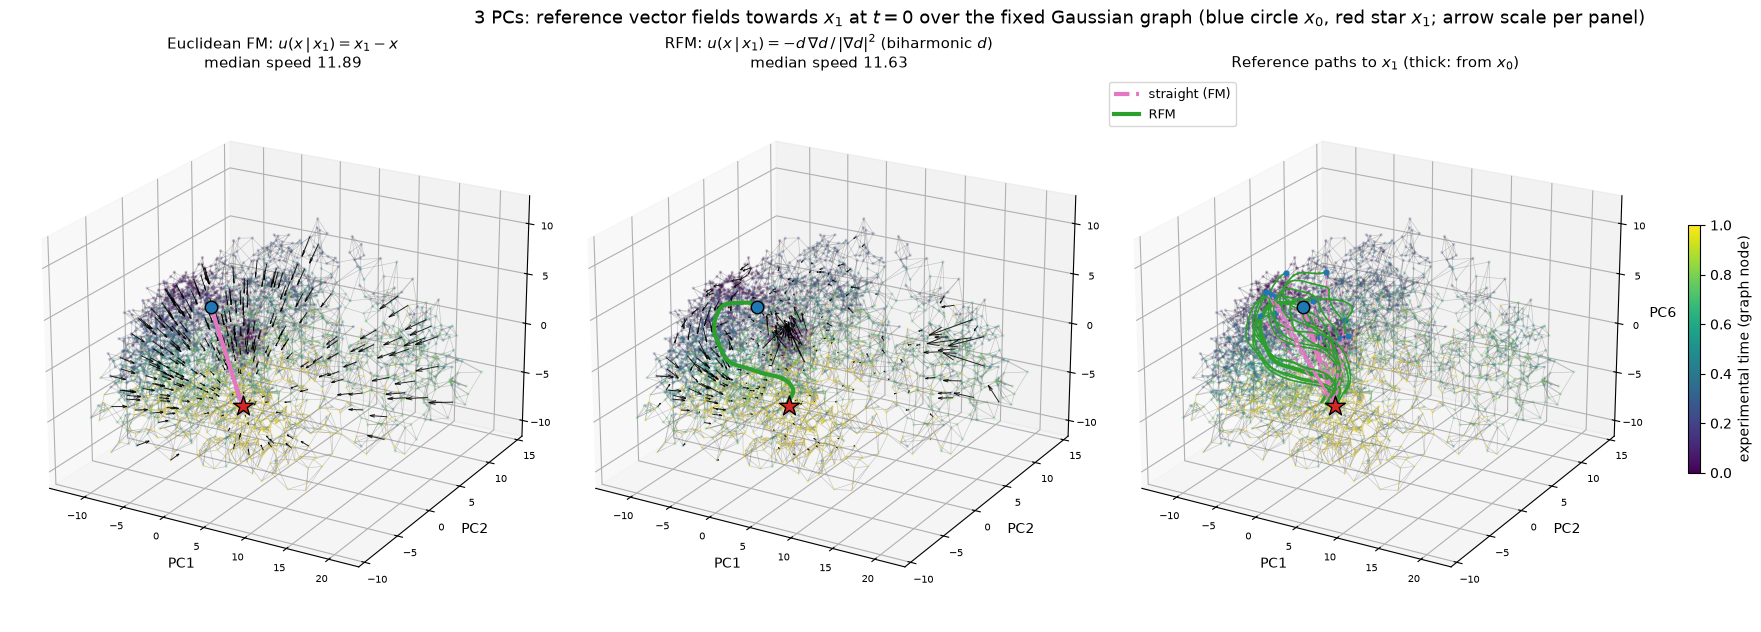

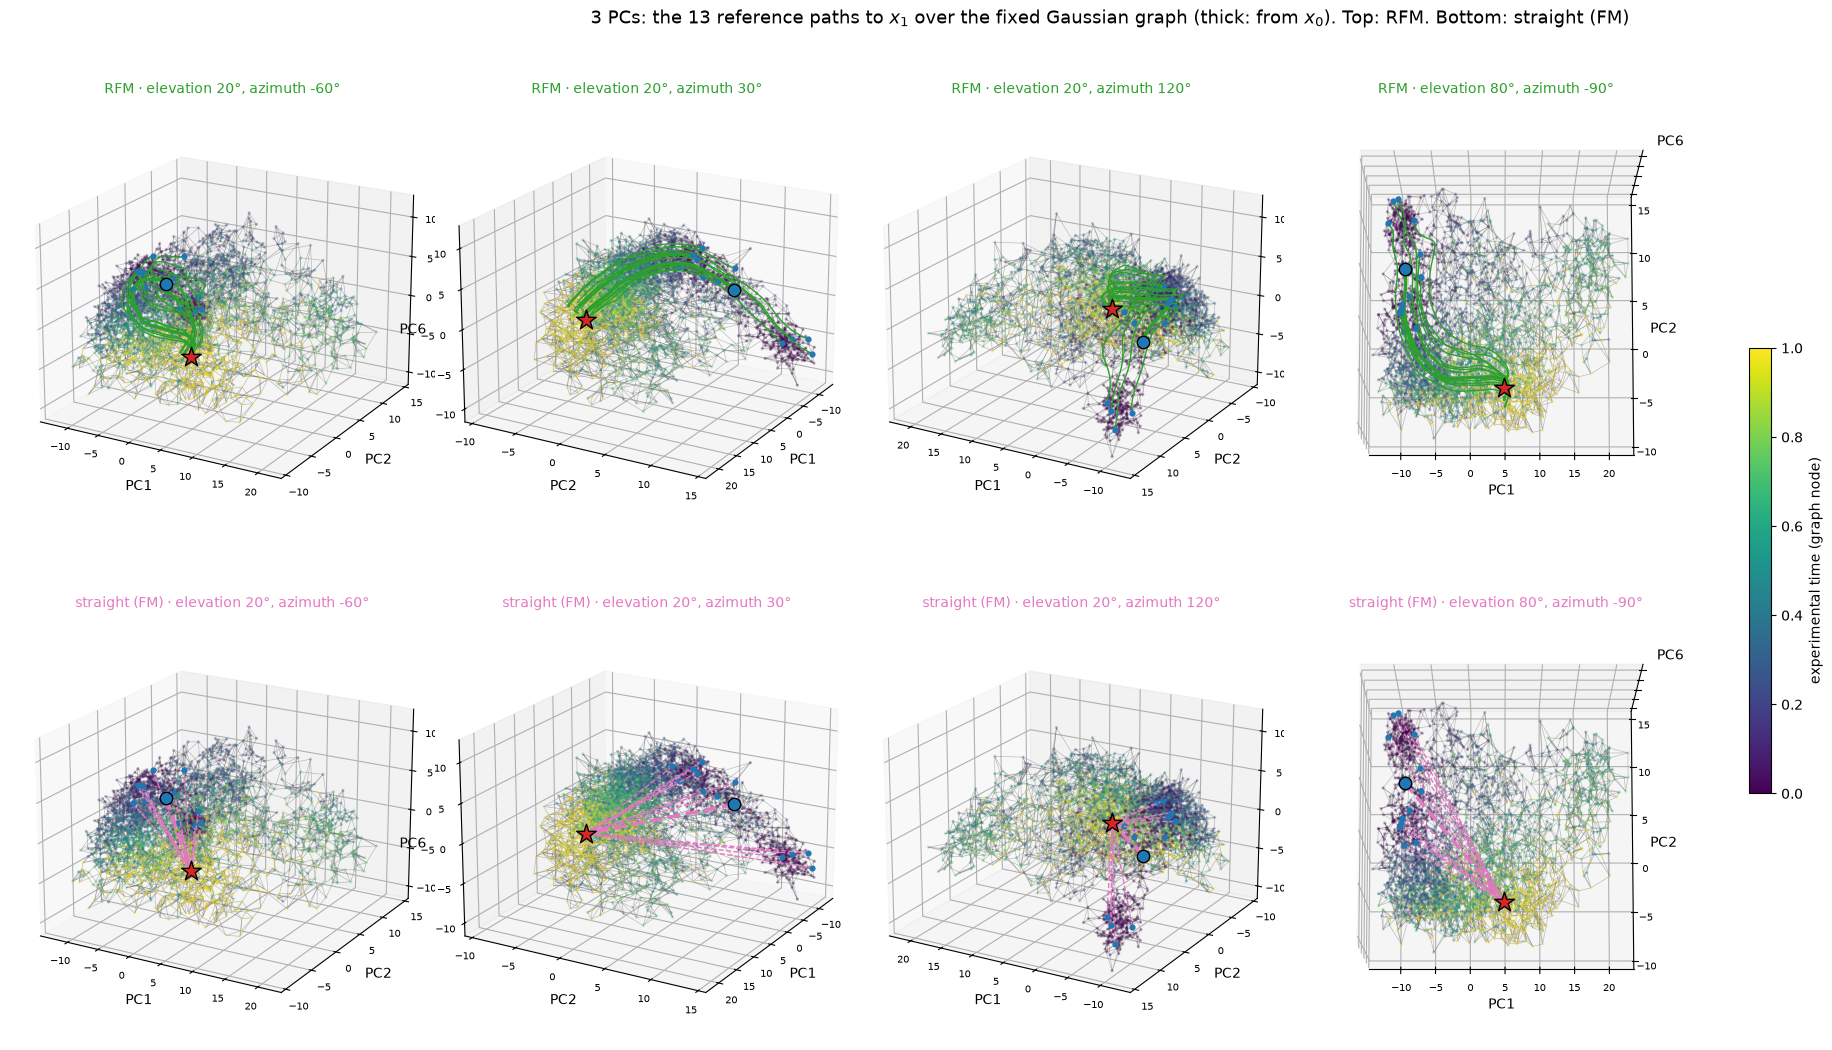

In [7]:
# 5 · the pair, the two reference fields, and their paths
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.sparse.csgraph import minimum_spanning_tree


def medoid(points):
    return points[cdist(points, points).mean(axis=1).argmin()]


def arrow_scale(fields, extent, frac=0.07):
    # common scale: the 90th-percentile speed is drawn as frac × the plot extent
    speeds = np.concatenate([np.linalg.norm(v, axis=1) for v in fields])
    return frac * extent / max(float(np.quantile(speeds, 0.9)), 1e-12)


def draw_arrows(ax, points, velocities, scale, extent, color="black", max_frac=0.14):
    a = velocities * scale
    length = np.linalg.norm(a, axis=1, keepdims=True)
    a = a * np.minimum(1.0, max_frac * extent / np.maximum(length, 1e-12))
    ax.quiver(*points.T, *a.T, length=1.0, normalize=False, arrow_length_ratio=0.3, color=color, linewidth=0.7,
              alpha=0.85, zorder=3)


def backdrop_edges(s):
    # each node's four heaviest edges (helper from section 4c) plus the minimum spanning tree by edge length:
    # the drawn subgraph is connected like the full graph, so long edges through sparse regions stay visible
    graph = s["cloud"].kernel.graph().tocsr()
    a, b, _ = strongest_edges(graph)
    length = graph.tocoo(copy=True)
    length.data = np.linalg.norm(s["points"][length.row] - s["points"][length.col], axis=1)
    tree = minimum_spanning_tree(length.tocsr()).tocoo()
    pairs = np.unique(np.vstack([np.c_[a, b], np.sort(np.c_[tree.row, tree.col], axis=1)]), axis=0)
    return pairs[:, 0], pairs[:, 1]


def draw_graph(ax, s, edge_alpha=0.35, node_alpha=0.2):
    # translucent backdrop: the backdrop edges (grey) and the graph nodes coloured by time.
    # The axes need computed_zorder=False, so that arrows (zorder 3), paths (4) and markers (5) stay on top.
    a, b = s["graph_edges"]
    ax.add_collection3d(Line3DCollection(np.stack([s["points"][a], s["points"][b]], axis=1), colors="dimgrey",
                                         linewidths=0.45, alpha=edge_alpha, zorder=1, rasterized=True))
    ax.scatter(*s["points"].T, c=s["point_time"], cmap="viridis", norm=TIME_NORM, s=2, alpha=node_alpha,
               depthshade=False, zorder=2, rasterized=True)


def draw_background(ax, s, alpha=0.06):
    ids = s["bg_ids"]
    ax.scatter(*s["X"][ids].T, c=time[ids], cmap="viridis", norm=TIME_NORM, s=2, alpha=alpha, depthshade=False,
               rasterized=True)


def mark_pair(ax, s):
    ax.scatter(*s["x0"], marker="o", s=80, color="tab:blue", edgecolors="black", zorder=5, depthshade=False)
    ax.scatter(*s["x1"], marker="*", s=220, color="tab:red", edgecolors="black", zorder=5, depthshade=False)


reference_rows = {}
for name, s in S.items():
    pts, pt = s["points"], s["point_time"]
    at = {t: pts[np.isclose(pt, t)] for t in time_levels}
    s["x0"], s["x1"] = medoid(at[source_time]), medoid(at[target_time])
    rng = np.random.default_rng(0)
    s["field_points"] = np.vstack([at[t][rng.choice(len(at[t]), 50, replace=False)] for t in time_levels])

    s["interp"] = RFMInterpolation(s["nystroem"], projection_fn=s["project"], max_velocity_norm=s["velocity_cap"])
    F = jnp.asarray(s["field_points"])
    s["u_rfm"] = np.asarray(jax.jit(s["interp"].u_t)(F, jnp.broadcast_to(jnp.asarray(s["x1"]), F.shape), 0.0))
    s["u_fm"] = s["x1"][None, :] - s["field_points"]

    others = at[source_time][np.random.default_rng(seed).choice(len(at[source_time]), 12, replace=False)]
    starts = np.vstack([s["x0"][None, :], others])
    path, proposed = kernels.integrate_euler_paths(s["interp"], starts, s["x1"], 0.99, 800)
    s["ref_times"] = np.linspace(0.0, 0.99, 801)
    s["rfm_paths"] = np.swapaxes(path, 0, 1)                                         # (13, 801, 3)
    s["fm_paths"] = starts[:, None, :] + s["ref_times"][None, :, None] * (s["x1"] - starts)[:, None, :]
    s["graph_edges"] = backdrop_edges(s)
    span = np.vstack([pts, s["rfm_paths"].reshape(-1, pts.shape[1]), s["fm_paths"].reshape(-1, pts.shape[1])])
    lo, hi = span.min(axis=0), span.max(axis=0)                                      # 3-D lines are not clipped
    s["graph_lims"] = list(zip(lo - 0.03 * (hi - lo), hi + 0.03 * (hi - lo)))
    rfm_len = np.linalg.norm(np.diff(s["rfm_paths"], axis=1), axis=-1).sum(axis=1)
    fm_len = np.linalg.norm(np.diff(s["fm_paths"], axis=1), axis=-1).sum(axis=1)
    speed_rfm, speed_fm = np.linalg.norm(s["u_rfm"], axis=1), np.linalg.norm(s["u_fm"], axis=1)
    reference_rows[name] = {
        "x0": np.round(s["x0"], 2).tolist(), "x1": np.round(s["x1"], 2).tolist(),
        "pair: RFM path length": rfm_len[0], "pair: straight length": fm_len[0],
        "pair: RFM end error (t=0.99)": float(np.linalg.norm(s["rfm_paths"][0, -1] - s["x1"])),
        "13 paths: mean RFM/straight length": float(np.mean(rfm_len / fm_len)),
        "13 paths: mean RFM end error": float(np.linalg.norm(s["rfm_paths"][:, -1] - s["x1"], axis=1).mean()),
        "RFM paths: max support ratio": float(s["cloud"].support_ratio(s["rfm_paths"]).max()),
        "straight paths: max support ratio": float(s["cloud"].support_ratio(s["fm_paths"]).max()),
        "RFM paths: clipped steps": float(np.mean(np.any(proposed < 0, axis=-1))) if s["clip"] else np.nan,
        "field: median speed RFM / FM": float(np.median(speed_rfm) / np.median(speed_fm)),
        "field: points at the RFM speed cap": float(np.mean(speed_rfm >= 0.999 * s["velocity_cap"])),
        "field: median cosine(RFM, FM)": float(np.median(np.sum(s["u_rfm"] * s["u_fm"], axis=1)
                                                         / np.maximum(speed_rfm * speed_fm, 1e-12))),
    }
display(pd.DataFrame(reference_rows))

for name, s in S.items():
    fig = plt.figure(figsize=(21, 6.4))
    axes = []
    panels = [(r"Euclidean FM: $u(x\,|\,x_1) = x_1 - x$", s["u_fm"], s["fm_paths"][0], MODEL_COLORS[CELLFLOW]),
              (r"RFM: $u(x\,|\,x_1) = -d\,\nabla d\,/\,|\nabla d|^2$ (biharmonic $d$)", s["u_rfm"], s["rfm_paths"][0],
               MODEL_COLORS["RFM + biharmonic OT"])]
    for k, (title, field, path, color) in enumerate(panels):
        ax = fig.add_subplot(1, 3, k + 1, projection="3d", computed_zorder=False)
        draw_graph(ax, s)
        draw_arrows(ax, s["field_points"], field, arrow_scale([field], s["extent"]), s["extent"])
        ax.plot(*path.T, color=color, lw=3, zorder=4)
        mark_pair(ax, s)
        setup_axes(ax, s)
        ax.set(xlim=s["graph_lims"][0], ylim=s["graph_lims"][1], zlim=s["graph_lims"][2])
        ax.set_title(f"{title}\nmedian speed {np.median(np.linalg.norm(field, axis=1)):.2f}", fontsize=11)
        axes.append(ax)
    ax = fig.add_subplot(1, 3, 3, projection="3d", computed_zorder=False)
    draw_graph(ax, s)
    for i in range(len(s["rfm_paths"])):
        lw = 3 if i == 0 else 1.2
        ax.plot(*s["fm_paths"][i].T, color=MODEL_COLORS[CELLFLOW], lw=lw, ls="--", zorder=4,
                label="straight (FM)" if i == 0 else None)
        ax.plot(*s["rfm_paths"][i].T, color=MODEL_COLORS["RFM + biharmonic OT"], lw=lw, zorder=4,
                label="RFM" if i == 0 else None)
        ax.scatter(*s["rfm_paths"][i, 0], s=12, color="tab:blue", depthshade=False, zorder=4)
    mark_pair(ax, s)
    setup_axes(ax, s)
    ax.set(xlim=s["graph_lims"][0], ylim=s["graph_lims"][1], zlim=s["graph_lims"][2])
    ax.set_title("Reference paths to $x_1$ (thick: from $x_0$)", fontsize=11)
    ax.legend(loc="upper left", fontsize=9)
    axes.append(ax)
    fig.subplots_adjust(left=0.0, right=0.94, top=0.88, bottom=0.02, wspace=0.0)
    time_colorbar(fig, axes, label="experimental time (graph node)")
    fig.suptitle(f"{name}: reference vector fields towards $x_1$ at $t=0$ over the {kernel_name} graph "
                 "(blue circle $x_0$, red star $x_1$; arrow scale per panel)", fontsize=13)
    plt.show()

    # the 13 reference paths over the graph from the four viewing angles of section 4c
    fig = plt.figure(figsize=(22, 11))
    axes = []
    rows = [("RFM", s["rfm_paths"], MODEL_COLORS["RFM + biharmonic OT"], "-"),
            ("straight (FM)", s["fm_paths"], MODEL_COLORS[CELLFLOW], "--")]
    for r, (label, paths, color, ls) in enumerate(rows):
        for c, (elev, azim) in enumerate(VIEW_ANGLES):
            ax = fig.add_subplot(2, 4, 4 * r + c + 1, projection="3d", computed_zorder=False)
            draw_graph(ax, s, edge_alpha=0.45, node_alpha=0.25)
            for i, p in enumerate(paths):
                ax.plot(*p.T, color=color, lw=2.5 if i == 0 else 1.0, ls=ls, zorder=4)
                ax.scatter(*p[0], s=12, color="tab:blue", depthshade=False, zorder=4)
            mark_pair(ax, s)
            setup_graph_axes(ax, s["graph_lims"], s["labels"], elev, azim)              # helper from section 4c
            ax.set_title(f"{label} · elevation {elev}°, azimuth {azim}°", fontsize=10, color=color)
            axes.append(ax)
    fig.subplots_adjust(left=0.0, right=0.93, top=0.92, bottom=0.02, wspace=0.0, hspace=0.08)
    time_colorbar(fig, axes, label="experimental time (graph node)")
    fig.suptitle(f"{name}: the 13 reference paths to $x_1$ over the {kernel_name} graph (thick: from $x_0$). "
                 "Top: RFM. Bottom: straight (FM)", fontsize=13)
    plt.show()

## Training the four variants

The models use the same network, optimizer (Adam, learning rate $10^{-3}$), initialization seed, batch size (64) and number of iterations (1,000). The RFM models interpolate in 32 Euler steps, with the scenario's clip and speed cap. The FM models use the zero-noise straight path. Each coupling is entropic OT with relative $\varepsilon=0.05$, recomputed on every batch: in the Nyström embedding for "biharmonic", on the coordinates for "Euclidean".

===== 3 PCs =====
[########################################] | 100% Completed | 102.29 ms
[########################################] | 100% Completed | 104.03 ms
[########################################] | 100% Completed | 101.46 ms
[########################################] | 100% Completed | 103.85 ms
[########################################] | 100% Completed | 101.36 ms
[########################################] | 100% Completed | 102.29 ms
[########################################] | 100% Completed | 101.21 ms
[########################################] | 100% Completed | 102.33 ms
[########################################] | 100% Completed | 101.22 ms
source (1859, 3), target (2555, 3); velocity-field parameters: 4,273,475
Training RFM + biharmonic OT
RFM + biharmonic OT: 56.1s; mean loss first 25 679.37629, last 25 450.68317
Training RFM + Euclidean OT
RFM + Euclidean OT: 26.5s; mean loss first 25 654.14221, last 25 355.30814
Training FM + biharmonic OT
FM + biharmonic OT: 14.6s

,training_seconds,mean_loss_first_25,mean_loss_last_25
RFM + biharmonic OT,56.1008,679.3763,450.6832
RFM + Euclidean OT,26.5344,654.1422,355.3081
FM + biharmonic OT,14.6095,39.1679,14.4483
FM + Euclidean OT,10.3855,31.7358,11.0262


[########################################] | 100% Completed | 101.57 ms
[########################################] | 100% Completed | 101.92 ms


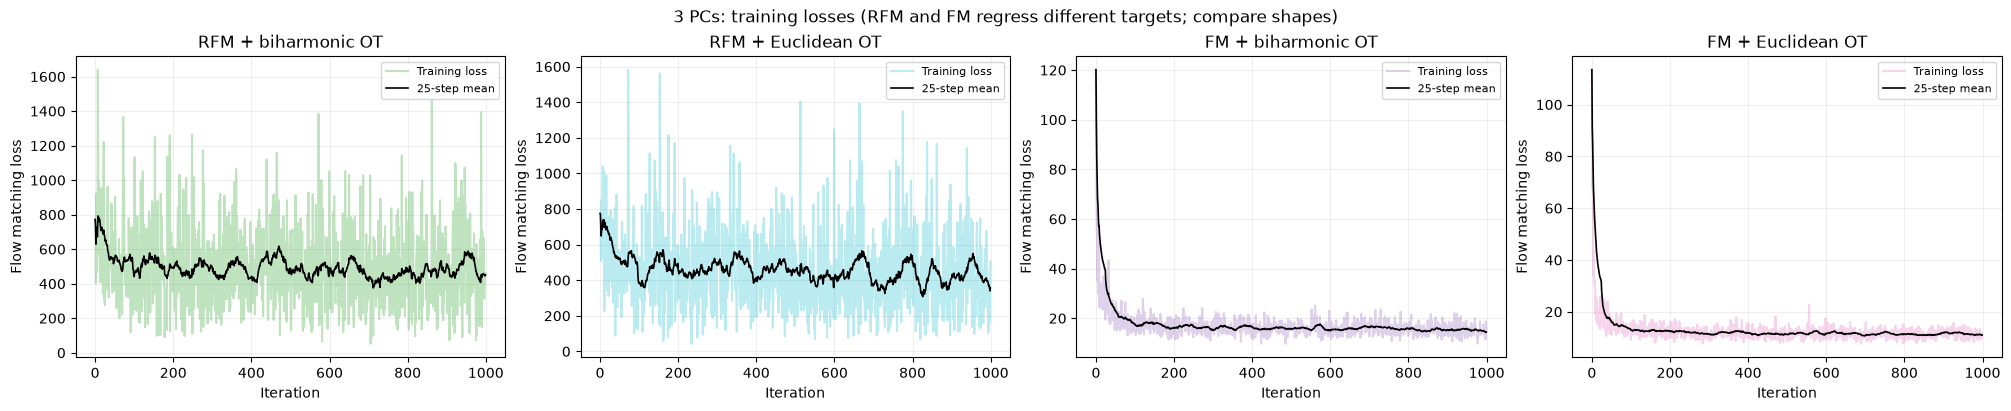

In [8]:
# 6 · train RFM / FM × biharmonic / Euclidean OT per view
def predict(model, starts):
    # solver.predict (Tsit5, PID rtol = atol = 1e-5) with the raised step limit
    _, condition, _ = flows.inference_inputs(model)
    out = np.asarray(model.solver.predict(np.asarray(starts, dtype=np.float32), condition, max_steps=max_ode_steps))
    assert out.shape == np.shape(starts) and np.all(np.isfinite(out))
    return out


def integrate_paths(model, starts, save_times, rtol=1e-5, atol=1e-5):
    # flows.integrate_learned_paths with the raised step limit; returns (paths, adaptive steps per start)
    state, condition, encoder_noise = flows.inference_inputs(model)

    def velocity(t, y, params):
        return state.apply_fn({"params": params}, t, y, condition, encoder_noise, train=False)[0]

    def one(params, y0):
        sol = diffrax.diffeqsolve(diffrax.ODETerm(velocity), diffrax.Tsit5(), t0=0.0, t1=1.0, dt0=None, y0=y0, args=params,
                                  stepsize_controller=diffrax.PIDController(rtol=rtol, atol=atol),
                                  saveat=diffrax.SaveAt(ts=jnp.asarray(save_times)), max_steps=max_ode_steps)
        return sol.ys, sol.stats["num_steps"]

    paths, steps = jax.jit(jax.vmap(one, in_axes=(None, 0)))(state.params, jnp.asarray(starts, dtype=jnp.float32))
    paths = np.asarray(paths)
    assert np.all(np.isfinite(paths))
    np.testing.assert_allclose(paths[:, 0], starts, rtol=1e-6, atol=1e-6)
    np.testing.assert_allclose(paths[:, -1], predict(model, starts), rtol=1e-4, atol=1e-4)
    return paths, np.asarray(steps)


for name, s in S.items():
    print(f"===== {name} =====", flush=True)
    src, tgt = cells_at(s, "train", source_time), cells_at(s, "train", target_time)
    s["train_adata"] = flows.make_toy_adata(src, tgt, target_key)
    embed = jax.jit(jax.vmap(s["nystroem"].extend_point))
    match_biharmonic = flows.make_entropic_match_fn(ot_epsilon, embed=embed)
    match_euclidean = flows.make_entropic_match_fn(ot_epsilon)
    rfm = flows.prepare_toy_model(
        s["train_adata"], "otrfm", target_key, **architecture, match_fn=match_biharmonic, nystroem=s["nystroem"],
        optimizer=optax.adam(1e-3), seed=seed,
        solver_kwargs={"interpolation_steps": interpolation_steps, "projection_fn": s["project"],
                       "project_to_manifold": False, "max_velocity_norm": s["velocity_cap"]},
    )
    s["models"] = {
        "RFM + biharmonic OT": rfm,
        "RFM + Euclidean OT": flows.build_matched_model(rfm, s["train_adata"], "otrfm", match_euclidean, target_key, seed,
                                                        nystroem=s["nystroem"]),
        "FM + biharmonic OT": flows.build_matched_model(rfm, s["train_adata"], "otfm", match_biharmonic, target_key, seed),
        "FM + Euclidean OT": flows.build_matched_model(rfm, s["train_adata"], "otfm", match_euclidean, target_key, seed),
    }
    print(f"source {src.shape}, target {tgt.shape}; velocity-field parameters: "
          f"{sum(p.size for p in jax.tree_util.tree_leaves(rfm.solver.vf_state.params)):,}")
    s["losses"], s["training_seconds"] = {}, {}
    display(comparison.train_untrained(s["models"], s["losses"], s["training_seconds"], num_iterations, batch_size).round(4))
    # predictions from arbitrary starts agree with the public predict API
    public = rfm.predict(s["train_adata"][s["train_adata"].obs[flows.SOURCE_KEY]].copy(),
                         covariate_data=pd.DataFrame({flows.SOURCE_KEY: [True], target_key: [True], "condition": [condition_name]}),
                         condition_id_key="condition", max_steps=max_ode_steps)
    np.testing.assert_allclose(predict(rfm, src), np.asarray(public[condition_name]), rtol=1e-4, atol=1e-4)

for name, s in S.items():
    plotting.plot_loss_panels(s["losses"], MODEL_COLORS, f"{name}: training losses (RFM and FM regress different targets; compare shapes)")

## Learned vector fields

$v_\theta(t, x)$ of each variant (inference weights, no dropout), at $t=0, 0.5, 1$, on the same 250 graph points as the reference fields. As above, the arrows show directions with one scale per panel. The magnitudes are in the panel titles and the table: the RFM fields are much faster near $t=0$ than later.

The learned field is a *marginal* field: it averages the conditional fields of all coupled pairs, so it is not expected to point at the one $x_1$ marked here. The table compares the variants with each other: the median cosine similarity with the CellFlow field (FM + Euclidean OT) at the same point and time, and the median speed.

3 PCs:


median speed                  \
                             0.0     0.5     1.0   
FM + Euclidean OT         13.879  13.972  11.976   
FM + biharmonic OT        13.511  11.429  11.361   
RFM + Euclidean OT        15.598  19.151  11.517   
RFM + biharmonic OT       16.563  19.960  12.794   

                    median cosine with CellFlow field                
                                                  0.0    0.5    1.0  
FM + Euclidean OT                               1.000  1.000  1.000  
FM + biharmonic OT                              0.988  0.981  0.982  
RFM + Euclidean OT                              0.899  0.817  0.667  
RFM + biharmonic OT                             0.846  0.819  0.764

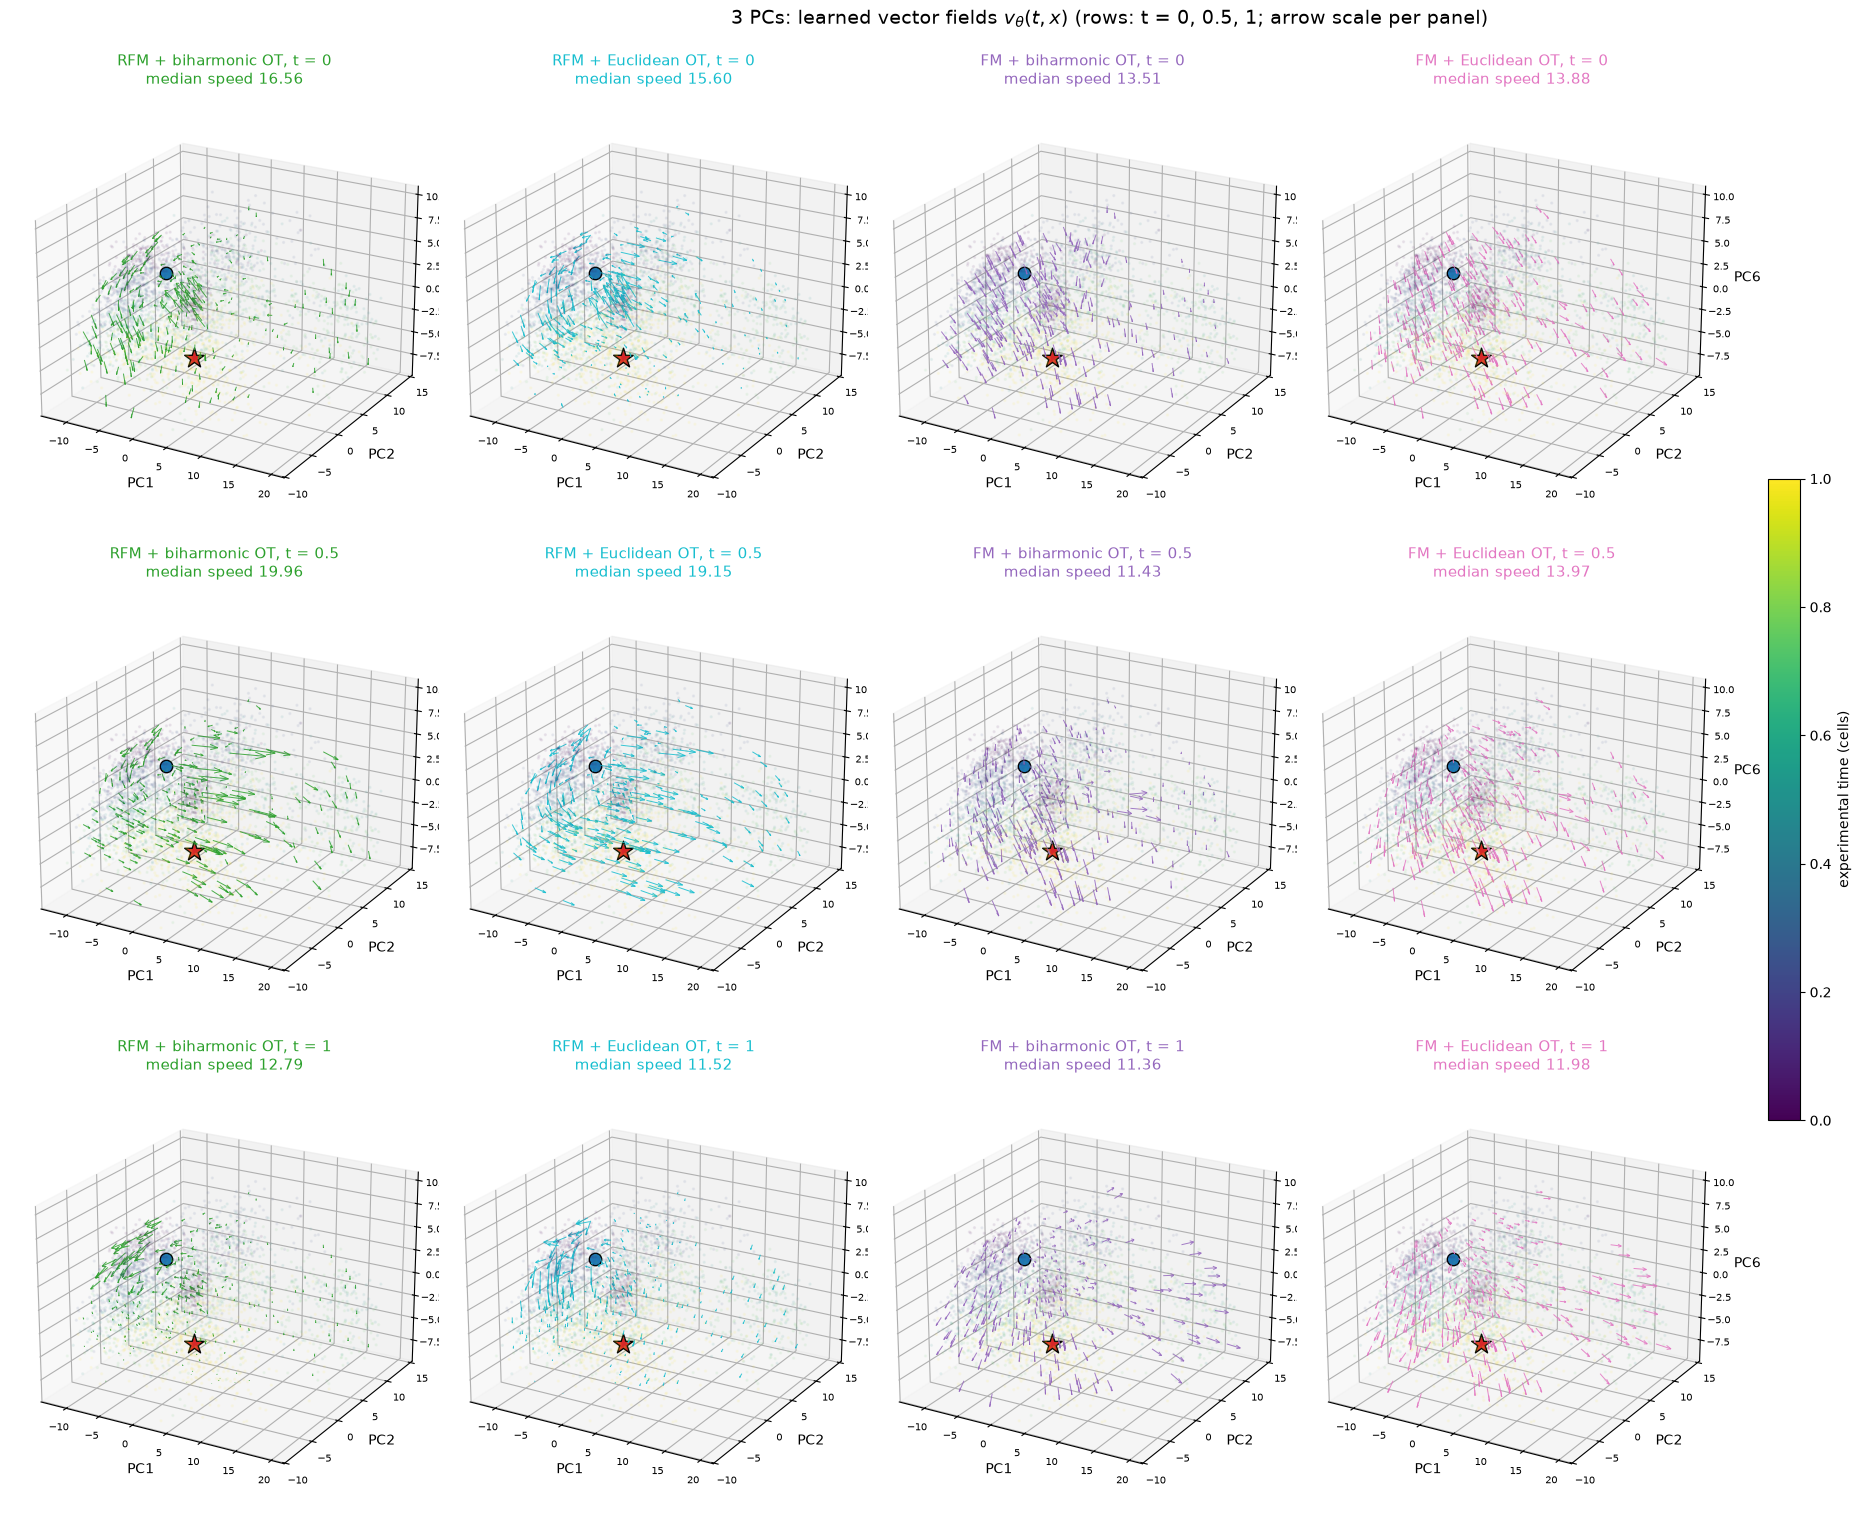

In [9]:
# 7 · learned fields at t = 0, 0.5, 1
field_times = (0.0, 0.5, 1.0)
for name, s in S.items():
    s["learned"] = {(m, t): flows.evaluate_learned_field(model, s["field_points"], t)
                    for m, model in s["models"].items() for t in field_times}
    rows = {}
    for (m, t), v in s["learned"].items():
        ref = s["learned"][CELLFLOW, t]
        cos = np.sum(v * ref, axis=1) / np.maximum(np.linalg.norm(v, axis=1) * np.linalg.norm(ref, axis=1), 1e-12)
        rows[(m, t)] = {"median speed": float(np.median(np.linalg.norm(v, axis=1))),
                        "median cosine with CellFlow field": float(np.median(cos))}
    print(f"{name}:")
    display(pd.DataFrame(rows).T.unstack(1).round(3))

    fig = plt.figure(figsize=(22, 15.5))
    axes = []
    for r, t in enumerate(field_times):
        for c, (m, model) in enumerate(s["models"].items()):
            ax = fig.add_subplot(len(field_times), 4, r * 4 + c + 1, projection="3d")
            draw_background(ax, s)
            v = s["learned"][m, t]
            draw_arrows(ax, s["field_points"], v, arrow_scale([v], s["extent"]), s["extent"], color=MODEL_COLORS[m])
            mark_pair(ax, s)
            setup_axes(ax, s)
            ax.set_title(f"{m}, t = {t:g}\nmedian speed {np.median(np.linalg.norm(v, axis=1)):.2f}", fontsize=11,
                         color=MODEL_COLORS[m])
            axes.append(ax)
    fig.subplots_adjust(left=0.0, right=0.94, top=0.93, bottom=0.01, wspace=0.0, hspace=0.12)
    time_colorbar(fig, axes)
    fig.suptitle(f"{name}: learned vector fields $v_\\theta(t, x)$ (rows: t = 0, 0.5, 1; arrow scale per panel)", fontsize=14)
    plt.show()

## Learned trajectories

Each variant's field is integrated from $x_0$ (thick line) and from 8 held-out test cells at $t=0$, with the predictor's Tsit5 settings and 101 saved times, without clipping. Dashed and dotted black lines show the reference RFM path and the straight path from $x_0$ to $x_1$. The backdrop is the same translucent kernel graph as in the reference-field figures, so you can see where the learned paths follow the cloud.

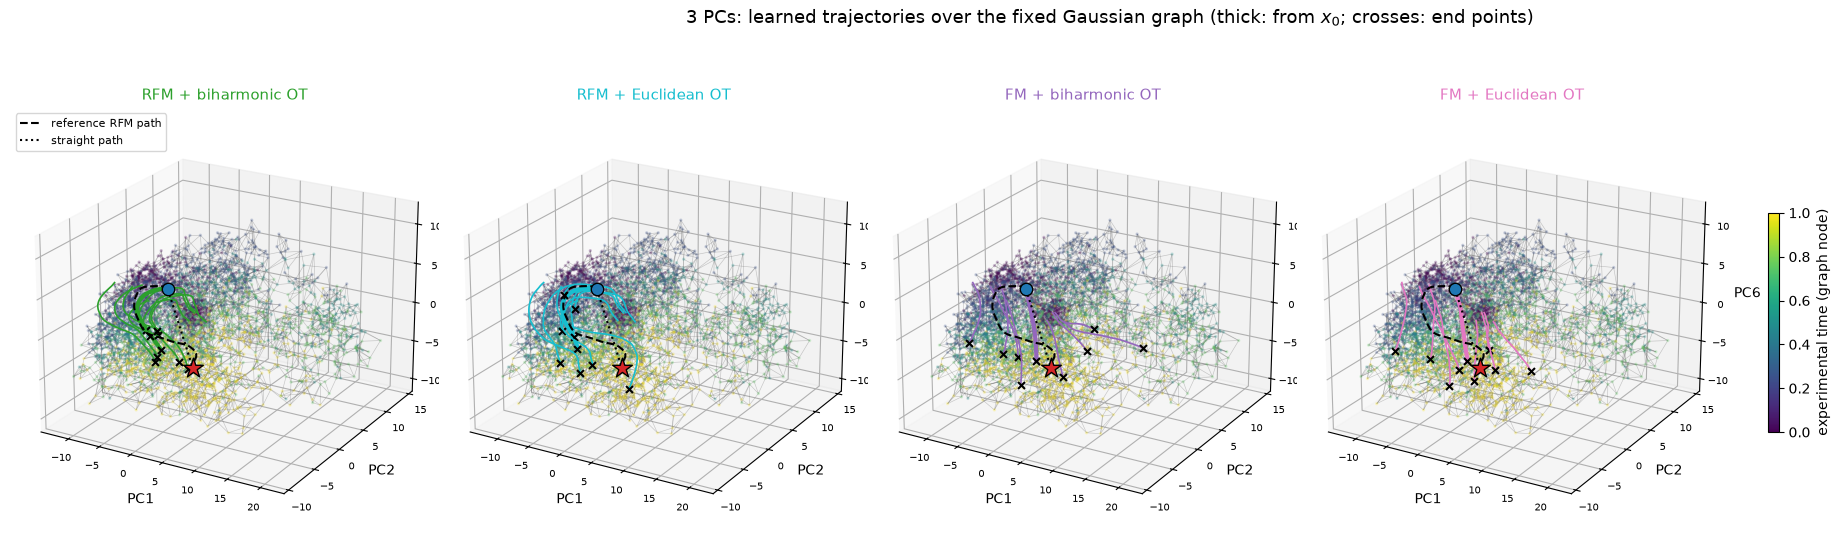

mean_path_length  paths_leaving_support  \
view  model                                                          
3 PCs RFM + biharmonic OT           20.2202                    0.0   
      RFM + Euclidean OT            18.3871                    0.0   
      FM + biharmonic OT            16.5384                    0.0   
      FM + Euclidean OT             16.7585                    0.0   

                           fraction_saved_points_supported  max_support_ratio  \
view  model                                                                     
3 PCs RFM + biharmonic OT                              1.0             0.4426   
      RFM + Euclidean OT                               1.0             0.3466   
      FM + biharmonic OT                               1.0             0.4354   
      FM + Euclidean OT                                1.0             0.4390   

                           median_distance_to_graph  \
view  model                                           
3 PCs RFM + biharmonic OT                    0.5543   
      RFM + Euclidean OT                     0.5061   
      FM + biharmonic OT                     0.6466   
      FM + Euclidean OT                      0.6445   

                           x0 path: end distance to x1  adaptive steps (max)  
view  model                                                                   
3 PCs RFM + biharmonic OT                       5.2749                1014.0  
      RFM + Euclidean OT                        7.2108                1050.0  
      FM + biharmonic OT                        3.9497                 773.0  
      FM + Euclidean OT                         2.5171                 749.0

In [10]:
# 8 · learned paths from x0 and eight test cells
path_times = np.linspace(0.0, 1.0, 101, dtype=np.float32)
path_rows = {}
for name, s in S.items():
    candidates = cells.unique_points(cells_at(s, "test", source_time))[0]
    starts = np.vstack([s["x0"][None, :], candidates[np.random.default_rng(2027).choice(len(candidates), 8, replace=False)]])
    s["learned_paths"], path_steps = {}, {}
    for m, model in s["models"].items():
        s["learned_paths"][m], path_steps[m] = integrate_paths(model, starts, path_times)
    for m, paths in s["learned_paths"].items():
        path_rows[(name, m)] = {**cells.path_metrics(s["cloud"], paths),
                                "x0 path: end distance to x1": float(np.linalg.norm(paths[0, -1] - s["x1"])),
                                "adaptive steps (max)": int(path_steps[m].max())}
    learned = np.concatenate([p.reshape(-1, p.shape[-1]) for p in s["learned_paths"].values()])
    lo = np.minimum([l for l, _ in s["graph_lims"]], learned.min(axis=0))     # every node and path inside the box
    hi = np.maximum([h for _, h in s["graph_lims"]], learned.max(axis=0))
    fig = plt.figure(figsize=(22, 5.8))
    axes = []
    for c, (m, paths) in enumerate(s["learned_paths"].items()):
        ax = fig.add_subplot(1, 4, c + 1, projection="3d", computed_zorder=False)
        draw_graph(ax, s)                                                       # translucent kernel graph (section 5)
        for i, p in enumerate(paths):
            ax.plot(*p.T, color=MODEL_COLORS[m], lw=3 if i == 0 else 1.2, zorder=4)
            ax.scatter(*p[-1], marker="x", s=25, color="black", depthshade=False, zorder=4)
        ax.plot(*s["rfm_paths"][0].T, color="black", lw=1.5, ls="--", zorder=4, label="reference RFM path")
        ax.plot(*s["fm_paths"][0].T, color="black", lw=1.5, ls=":", zorder=4, label="straight path")
        mark_pair(ax, s)
        setup_axes(ax, s)
        ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]))
        ax.set_title(m, fontsize=11, color=MODEL_COLORS[m])
        axes.append(ax)
    axes[0].legend(loc="upper left", fontsize=8)
    fig.subplots_adjust(left=0.0, right=0.94, top=0.86, bottom=0.02, wspace=0.0)
    time_colorbar(fig, axes, label="experimental time (graph node)")
    fig.suptitle(f"{name}: learned trajectories over the {kernel_name} graph (thick: from $x_0$; crosses: end points)",
                 fontsize=13)
    plt.show()

path_table = pd.DataFrame(path_rows).T.rename_axis(["view", "model"])
display(path_table.drop(columns=["paths_with_negative_expression"]).round(4))

## Comparison on held-out cells

**Endpoints.** The $t=0$ cells of a split are pushed through each learned field and compared with the same split's $t=1$ cells:

- squared energy distance;
- empirical $W_2$ (exact assignment on subsamples of at most 1,500 cells);
- the error of the mean;
- support diagnostics.

Two references bracket the models: the unchanged source and the training $t=1$ cells (the finite-sample floor).

**Intermediate days.** The validation $t=0$ cells are integrated to $t=0.25, 0.5, 0.75$ and compared with the validation cells observed on those days. Model time is not tied to experimental time, so this asks more than the models were trained for.

In [11]:
# 9 · endpoint and intermediate metrics
drop = {"3 genes": [], "3 PCs": ["negative_expression_fraction"]}   # sign is meaningless for PCA scores
endpoint_tables, intermediate_tables = {}, {}
inter_times = np.array([0.0, 0.25, 0.5, 0.75, 1.0], dtype=np.float32)
for name, s in S.items():
    s["predicted"], tables = {}, {}
    for split_name in ("val", "test"):
        source, target = cells_at(s, split_name, source_time), cells_at(s, split_name, target_time)
        preds = {m: predict(model, source) for m, model in s["models"].items()}
        s["predicted"][split_name] = preds
        tables[split_name] = cells.metric_table({"unchanged source": source, "training t=1 cells (floor)": cells_at(s, "train", target_time),
                                                 **preds}, target, s["cloud"])
    endpoint_tables[name] = pd.concat(tables, names=["split", "cloud"]).drop(columns=drop[name])

    source = cells_at(s, "val", source_time)
    states, s["val_steps"] = {}, {}
    for m, model in s["models"].items():
        states[m], s["val_steps"][m] = integrate_paths(model, source, inter_times)
    rows = []
    for k, t in enumerate(inter_times[1:-1], start=1):
        clouds = {"unchanged source": source, "training cells of the day (floor)": cells_at(s, "train", t),
                  **{m: states[m][:, k] for m in states}}
        rows.append(cells.metric_table(clouds, cells_at(s, "val", t), s["cloud"]).assign(time=float(t)).rename_axis("cloud").reset_index())
    intermediate_tables[name] = pd.concat(rows).set_index(["time", "cloud"]).drop(columns=drop[name])

for name in S:
    print(f"===== {name}: endpoints at t=1 =====")
    display(endpoint_tables[name].round(4))
    print(f"===== {name}: intermediate days (val) =====")
    display(intermediate_tables[name][["energy_distance_squared", "wasserstein_2", "mean_error_to_target", "unsupported_fraction"]].round(4))

===== 3 PCs: endpoints at t=1 =====


energy_distance_squared  wasserstein_2  \
split cloud                                                                
val   unchanged source                            20.2401        17.8092   
      training t=1 cells (floor)                   0.0298         1.8030   
      RFM + biharmonic OT                          1.7479         4.9470   
      RFM + Euclidean OT                           1.1746         4.6737   
      FM + biharmonic OT                           0.2727         2.6716   
      FM + Euclidean OT                            0.1221         2.6424   
test  unchanged source                            20.7660        18.1136   
      training t=1 cells (floor)                   0.0142         1.4672   
      RFM + biharmonic OT                          1.9660         5.0708   
      RFM + Euclidean OT                           1.6093         5.0686   
      FM + biharmonic OT                           0.3274         2.6995   
      FM + Euclidean OT                            0.1763         2.6022   

                                  mean_error_to_target  unsupported_fraction  \
split cloud                                                                    
val   unchanged source                         16.7849                   0.0   
      training t=1 cells (floor)                0.4603                   0.0   
      RFM + biharmonic OT                       3.3654                   0.0   
      RFM + Euclidean OT                        3.2417                   0.0   
      FM + biharmonic OT                        1.4753                   0.0   
      FM + Euclidean OT                         0.6173                   0.0   
test  unchanged source                         17.1634                   0.0   
      training t=1 cells (floor)                0.3302                   0.0   
      RFM + biharmonic OT                       3.6475                   0.0   
      RFM + Euclidean OT                        3.9637                   0.0   
      FM + biharmonic OT                        1.6003                   0.0   
      FM + Euclidean OT                         0.8488                   0.0   

                                  median_distance_to_graph  diverged_fraction  
split cloud                                                                    
val   unchanged source                              0.5115                0.0  
      training t=1 cells (floor)                    0.4384                0.0  
      RFM + biharmonic OT                           0.5712                0.0  
      RFM + Euclidean OT                            0.4771                0.0  
      FM + biharmonic OT                            0.5596                0.0  
      FM + Euclidean OT                             0.5981                0.0  
test  unchanged source                              0.5136                0.0  
      training t=1 cells (floor)                    0.4384                0.0  
      RFM + biharmonic OT                           0.5160                0.0  
      RFM + Euclidean OT                            0.4528                0.0  
      FM + biharmonic OT                            0.5864                0.0  
      FM + Euclidean OT                             0.5814                0.0

===== 3 PCs: intermediate days (val) =====


energy_distance_squared  \
time cloud                                                        
0.25 unchanged source                                    5.6293   
     training cells of the day (floor)                   0.0233   
     RFM + biharmonic OT                                 1.8031   
     RFM + Euclidean OT                                  2.0615   
     FM + biharmonic OT                                  2.7961   
     FM + Euclidean OT                                   2.7587   
0.50 unchanged source                                   13.1244   
     training cells of the day (floor)                   0.0464   
     RFM + biharmonic OT                                 3.7313   
     RFM + Euclidean OT                                  4.0813   
     FM + biharmonic OT                                  3.6042   
     FM + Euclidean OT                                   3.3444   
0.75 unchanged source                                   15.6533   
     training cells of the day (floor)                   0.0288   
     RFM + biharmonic OT                                 3.2387   
     RFM + Euclidean OT                                  3.4501   
     FM + biharmonic OT                                  1.6124   
     FM + Euclidean OT                                   1.6322   

                                        wasserstein_2  mean_error_to_target  \
time cloud                                                                    
0.25 unchanged source                          9.6773                7.8033   
     training cells of the day (floor)         1.8535                0.3468   
     RFM + biharmonic OT                       6.7817                3.5262   
     RFM + Euclidean OT                        7.0371                3.8611   
     FM + biharmonic OT                        6.9391                4.7604   
     FM + Euclidean OT                         6.9814                4.8352   
0.50 unchanged source                         15.6965               13.3959   
     training cells of the day (floor)         1.9108                0.7803   
     RFM + biharmonic OT                      10.8589                6.4322   
     RFM + Euclidean OT                       11.1716                7.0449   
     FM + biharmonic OT                        8.4207                5.4350   
     FM + Euclidean OT                         8.5001                5.4389   
0.75 unchanged source                         16.8049               15.0051   
     training cells of the day (floor)         2.0294                0.3122   
     RFM + biharmonic OT                       9.2831                5.9772   
     RFM + Euclidean OT                       10.0733                6.3213   
     FM + biharmonic OT                        5.8931                3.2978   
     FM + Euclidean OT                         6.2660                3.3883   

                                        unsupported_fraction  
time cloud                                                    
0.25 unchanged source                                    0.0  
     training cells of the day (floor)                   0.0  
     RFM + biharmonic OT                                 0.0  
     RFM + Euclidean OT                                  0.0  
     FM + biharmonic OT                                  0.0  
     FM + Euclidean OT                                   0.0  
0.50 unchanged source                                    0.0  
     training cells of the day (floor)                   0.0  
     RFM + biharmonic OT                                 0.0  
     RFM + Euclidean OT                                  0.0  
     FM + biharmonic OT                                  0.0  
     FM + Euclidean OT                                   0.0  
0.75 unchanged source                                    0.0  
     training cells of the day (floor)                   0.0  
     RFM + biharmonic OT                                 0.0  
     RFM + Euclidean OT                        

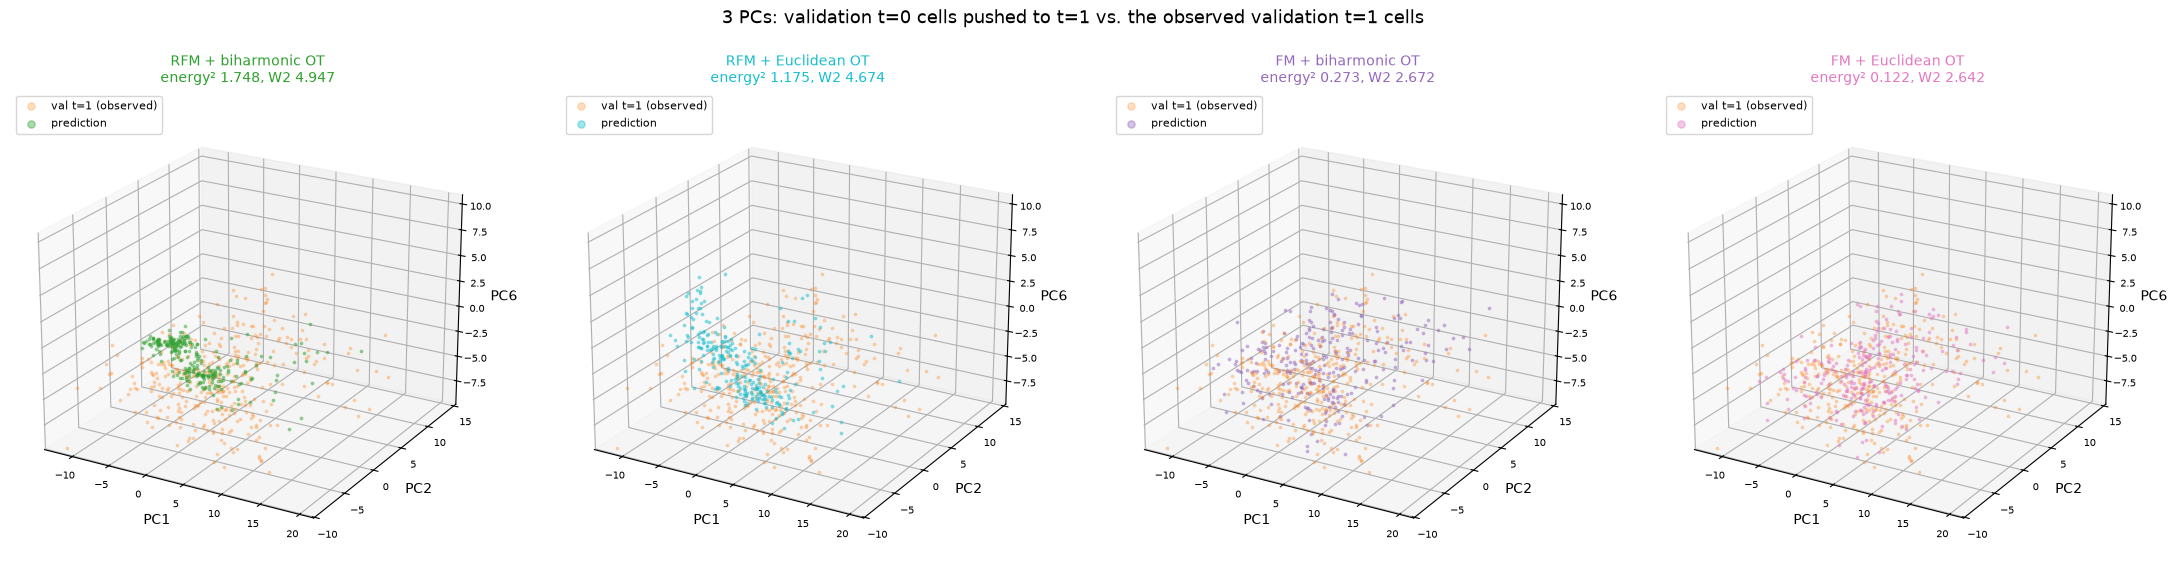

In [12]:
# 10 · predicted t=1 clouds (validation) in 3-D
for name, s in S.items():
    target = cells_at(s, "val", target_time)
    fig = plt.figure(figsize=(22, 5.8))
    for c, (m, pred) in enumerate(s["predicted"]["val"].items()):
        ax = fig.add_subplot(1, 4, c + 1, projection="3d")
        ax.scatter(*target.T, s=3, alpha=0.25, color="tab:orange", depthshade=False, label="val t=1 (observed)")
        ax.scatter(*pred.T, s=3, alpha=0.4, color=MODEL_COLORS[m], depthshade=False, label="prediction")
        setup_axes(ax, s)
        e = endpoint_tables[name].loc[("val", m)]
        ax.set_title(f"{m}\nenergy² {e.energy_distance_squared:.3f}, W2 {e.wasserstein_2:.3f}", fontsize=10, color=MODEL_COLORS[m])
        ax.legend(loc="upper left", fontsize=8, markerscale=3)
    fig.subplots_adjust(left=0.0, right=1.0, top=0.84, bottom=0.02, wspace=0.0)
    fig.suptitle(f"{name}: validation t=0 cells pushed to t=1 vs. the observed validation t=1 cells", fontsize=13)
    plt.show()

In [13]:
# 11 · summary: one row per view and model
summary = {}
for name, s in S.items():
    for m in s["models"]:
        e = endpoint_tables[name]
        inter = intermediate_tables[name].xs(m, level="cloud")
        summary[(name, m)] = {
            "val energy²": e.loc[("val", m), "energy_distance_squared"],
            "test energy²": e.loc[("test", m), "energy_distance_squared"],
            "val W2": e.loc[("val", m), "wasserstein_2"],
            "test W2": e.loc[("test", m), "wasserstein_2"],
            "val mean error": e.loc[("val", m), "mean_error_to_target"],
            "intermediate energy² (mean)": inter["energy_distance_squared"].mean(),
            "intermediate W2 (mean)": inter["wasserstein_2"].mean(),
            "val predictions unsupported": e.loc[("val", m), "unsupported_fraction"],
            "path length": path_table.loc[(name, m), "mean_path_length"],
            "adaptive steps per val cell (median)": float(np.median(s["val_steps"][m])),
            "adaptive steps per val cell (max)": int(s["val_steps"][m].max()),
            "training s": s["training_seconds"][m],
        }
    for ref in ("unchanged source", "training t=1 cells (floor)"):
        e = endpoint_tables[name]
        summary[(name, ref)] = {"val energy²": e.loc[("val", ref), "energy_distance_squared"],
                                "test energy²": e.loc[("test", ref), "energy_distance_squared"],
                                "val W2": e.loc[("val", ref), "wasserstein_2"], "test W2": e.loc[("test", ref), "wasserstein_2"]}
summary_table = pd.DataFrame.from_dict(summary, orient="index").rename_axis(["view", "model"])
display(summary_table.round(4))

val energy²  test energy²   val W2  test W2  \
view  model                                                                     
3 PCs RFM + biharmonic OT              1.7479        1.9660   4.9470   5.0708   
      RFM + Euclidean OT               1.1746        1.6093   4.6737   5.0686   
      FM + biharmonic OT               0.2727        0.3274   2.6716   2.6995   
      FM + Euclidean OT                0.1221        0.1763   2.6424   2.6022   
      unchanged source                20.2401       20.7660  17.8092  18.1136   
      training t=1 cells (floor)       0.0298        0.0142   1.8030   1.4672   

                                  val mean error  intermediate energy² (mean)  \
view  model                                                                     
3 PCs RFM + biharmonic OT                 3.3654                       2.9244   
      RFM + Euclidean OT                  3.2417                       3.1976   
      FM + biharmonic OT                  1.4753                       2.6709   
      FM + Euclidean OT                   0.6173                       2.5784   
      unchanged source                       NaN                          NaN   
      training t=1 cells (floor)             NaN                          NaN   

                                  intermediate W2 (mean)  \
view  model                                                
3 PCs RFM + biharmonic OT                         8.9746   
      RFM + Euclidean OT                          9.4273   
      FM + biharmonic OT                          7.0843   
      FM + Euclidean OT                           7.2492   
      unchanged source                               NaN   
      training t=1 cells (floor)                     NaN   

                                  val predictions unsupported  path length  \
view  model                                                                  
3 PCs RFM + biharmonic OT                                 0.0      20.2202   
      RFM + Euclidean OT                                  0.0      18.3871   
      FM + biharmonic OT                                  0.0      16.5384   
      FM + Euclidean OT                                   0.0      16.7585   
      unchanged source                                    NaN          NaN   
      training t=1 cells (floor)                          NaN          NaN   

                                  adaptive steps per val cell (median)  \
view  model                                                              
3 PCs RFM + biharmonic OT                                       1007.0   
      RFM + Euclidean OT                                         985.5   
      FM + biharmonic OT                                         684.0   
      FM + Euclidean OT                                          664.0   
      unchanged source                                             NaN   
      training t=1 cells (floor)                                   NaN   

                                  adaptive steps per val cell (max)  \
view  model                                                           
3 PCs RFM + biharmonic OT                                    1207.0   
      RFM + Euclidean OT                                     1176.0   
      FM + biharmonic OT                                      937.0   
      FM + Euclidean OT                                       892.0   
      unchanged source                                          NaN   
      training t=1 cells (floor)                                NaN   

                                  training s  
view  model                                   
3 PCs RFM + biharmonic OT            56.1008  
      RFM + Euclidean OT             26.5344  
      FM + biharmonic OT             14.6095  
      FM + Euclidean OT              10.3855  
      unchanged source                   NaN  
      training t=1 cells (floor)         NaN

## Reading the results

These numbers come from the saved run: one GPU, seed 2026, 1,000 iterations per model.

**Run-to-run noise.** FM + Euclidean OT does not use the kernel, so it is the same model as in `riemannian_eb_scenarios_3d.ipynb`, with the same data, split, seed and batches. Over four runs, two per notebook, its validation energy² was 0.12 and 0.26 here and 0.15 and 0.10 there. GPU training is not bit-reproducible, and over 1,000 iterations the small differences grow to a factor of about 2.5 in this metric. Differences of that size between single runs are therefore not rankings.

**3 genes: there is no fixed-Gaussian geometry.**

- **The default graph falls apart.** The default $\sigma = 0.144$ is set by the dense COL3A1 = 0 sheet. At this σ, 533 of the 220,866 CkNN edges get weight exactly zero in float32. The graph splits into 6 components (2,200, 1,455, 302, 22, … points): the sheet and the expressing cells separate.
- **A larger σ connects it only formally.** With σ raised 2–4×, the graph is connected, but $\lambda_2$ is zero to numerical precision. The biharmonic geometry would then reduce to one coordinate that only says on which side of the gap a cell lies.
- **The variable Gaussian does not have this problem.** It adapts its bandwidth to the local density and bridges the gap ($\lambda_2 = 0.006$).

**3 PCs**

- **Geometry: connected but weakly.** All CkNN edges are kept, but $\lambda_2 = 0.078$, against 1.65 for the variable Gaussian. The fixed bandwidth attaches the sparse outer cells only weakly (smallest degree 0.21).
- **Reference field: slower than before, and less accurate.**
  - The RFM field now has about the speed of the FM field (median ratio 0.98, against 5.7 with the variable Gaussian) and a similar direction (median cosine 0.80).
  - Its Euler paths to $t=0.99$ stop on average 1.3 short of the target (0.48 for the pair $x_0$, $x_1$), against 0.006 with the variable Gaussian.
  - Paths are 1.3× the straight length, as with the variable Gaussian, and stay inside the support.
- **Learned fields: the early speed burst is gone.** RFM median speeds are 16–17 at $t=0$, 19–20 at $t=0.5$ and 12–13 at $t=1$. FM stays at 11–14 throughout.
- **Endpoints (energy², val / test): FM is clearly better.** For reference, the floor is 0.03 / 0.01 and the unchanged source 20.2 / 20.8.

  | Model | val | test |
  | --- | --- | --- |
  | FM + Euclidean OT (CellFlow) | 0.12 | 0.18 |
  | FM + biharmonic OT | 0.27 | 0.33 |
  | RFM + Euclidean OT | 1.17 | 1.61 |
  | RFM + biharmonic OT | 1.75 | 1.97 |

  The RFM predictions concentrate on one side of the target cloud (section 10), which fits reference paths that stop short.
- **Intermediate days: FM is slightly ahead.** By mean energy² the order is FM + Euclidean 2.58, FM + biharmonic 2.67, RFM + biharmonic 2.92, RFM + Euclidean 3.20. By mean $W_2$ it is FM + biharmonic 7.1, FM + Euclidean 7.2, RFM + biharmonic 9.0, RFM + Euclidean 9.4. RFM is ahead at $t=0.25$ (energy² 1.8–2.1 against 2.8) and behind at $t=0.75$ (3.2–3.5 against 1.6).

**Against the variable Gaussian** (`riemannian_eb_scenarios_3d.ipynb`)

- **The fixed Gaussian cannot build the gene-view geometry.**
- **In the PCA view, its RFM endpoints are somewhat further off** (validation energy² 1.17–1.75 against 1.05–1.18; in the previous pair of runs 1.39–1.42 against 0.71–0.73). That is within the run-to-run noise of FM + Euclidean OT.
- **Its RFM fits the intermediate days worse.** Mean $W_2$ is 9.0–9.4 here against 6.5 with the variable Gaussian, while FM is at 7.1–7.6 in both notebooks. The previous pair of runs showed the same gap (8.3–9.1 against 6.35 for RFM + biharmonic).
- **Two diagnostics that need no training also favour the variable Gaussian:** a 21× larger $\lambda_2$, and exact reference paths that reach their target (0.006 against 1.3 off).
- **It removes the early speed burst** of the variable-Gaussian RFM fields.